# 🏨 Predicción de Cancelación de Reservas Hoteleras
##  Máster en Data Science & IA · Evolve Academy

**Dataset:** Hotel Booking Demand — Antonio, Almeida & Nunes (2019)  
**Tarea:** Clasificación binaria · `is_canceled` (37% positivos)   
**Objetivo** es Predecir aquellas reservas que tienen una alta probabilidad de ser cancaledas.  


## 0. Entorno y dependencias

In [93]:
# Instalar dependencias si es necesario
# !pip install pandas scikit-learn xgboost lightgbm optuna dalex shap imbalanced-learn matplotlib seaborn

In [94]:
# Configuración general del entorno.
import warnings
warnings.filterwarnings("ignore")  # Oculto avisos que no afectan al resultado, para que la salida quede más limpia.

# Manejo de datos y cálculo numérico.
import numpy as np
import pandas as pd

# Visualización de gráficos.
import matplotlib.pyplot as plt
# import matplotlib.ticker as mticker  # Pensado para dar formato a los ejes en porcentaje, pero no se ha llegado a aplicar.
# import seaborn as sns  # Se importó como alternativa para los gráficos, pero finalmente todo se ha hecho con matplotlib.

# Construcción del flujo de preprocesado y modelado.
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # Escalado de variables numéricas y codificación de categóricas.

# Modelos de clasificación.
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
# import xgboost as xgb  # No se usa directamente, ya que el modelo se construye siempre a través de XGBClassifier.

# Métricas de evaluación sobre el conjunto de test.
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,  # Métricas numéricas, en el mismo orden en que se imprimen en el notebook.
    ConfusionMatrixDisplay, RocCurveDisplay  # Gráficos de evaluación del modelo.
)
# from sklearn.metrics import classification_report, confusion_matrix
# Se probaron en un primer momento, pero se optó por las métricas individuales y por ConfusionMatrixDisplay.from_predictions en su lugar.

# Validación y partición de los datos respetando el orden temporal.
from sklearn.model_selection import TimeSeriesSplit
# from sklearn.model_selection import cross_val_score  # Se pensó usar para la validación, pero finalmente se ha optado por TimeSeriesSplit de forma manual.

# Gestión del desbalanceo de clases.
from sklearn.utils.class_weight import compute_sample_weight

# Optimización de hiperparámetros.
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)  # Reduzco los mensajes de Optuna para no saturar la salida.

# Librerías que se probaron en un primer momento pero que finalmente no se han usado en el trabajo.
# import lightgbm as lgb  # Se planteó como modelo adicional a comparar, pero no se ha llegado a entrenar.
# import dalex as dx  # Se planteó como alternativa para la interpretabilidad, pero finalmente se ha usado SHAP.

# Interpretabilidad del modelo.
import shap

# Opciones de visualización de pandas y semilla para que los resultados sean reproducibles.
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)
RANDOM_STATE = 42

## 1. Carga y primera inspección

El dataset es público y está disponible directamente desde el repositorio de TidyTuesday (espejo del paper original).  
También puede descargarse desde Kaggle: `jessemostipak/hotel-booking-demand`.


In [95]:
# Carga del dataset
df = pd.read_csv("reservas_hoteleras.csv")

# Si se usa la extensión xlsx con el dataset sería
# df = pd.read_excel("reservas_hoteleras.xlsx")

In [96]:
# Visualización de las primeras filas del dataset
df.head(3)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0000,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0000,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0000,0,0,Check-Out,2015-07-02


In [97]:
# Comprobación del número de registros y variables del conjunto de datos.
print(f"El dataset contiene {df.shape[0]:,} registros y {df.shape[1]} variables.")

El dataset contiene 119,390 registros y 32 variables.


### Diccionario de variables
*Fuente: Antonio, Almeida & Nunes (2019). Hotel booking demand datasets. Data in Brief, 22, 41–49.*

| Variable | Tipo | Descripción |
|---|---|---|
| `hotel` | Categórica | Tipo de hotel: H1 = Resort Hotel, H2 = City Hotel |
| `is_canceled` | Binaria (target) | 1 = reserva cancelada, 0 = no cancelada |
| `lead_time` | Numérica | Días entre la fecha de reserva y la fecha de llegada |
| `arrival_date_year` | Numérica | Año de llegada |
| `arrival_date_month` | Categórica | Mes de llegada |
| `arrival_date_week_number` | Numérica | Semana del año de llegada |
| `arrival_date_day_of_month` | Numérica | Día del mes de llegada |
| `stays_in_weekend_nights` | Numérica | Noches de fin de semana (sáb/dom) reservadas o estancia real |
| `stays_in_week_nights` | Numérica | Noches entre semana (lun–vie) reservadas o estancia real |
| `adults` | Numérica | Número de adultos |
| `children` | Numérica | Número de niños |
| `babies` | Numérica | Número de bebés |
| `meal` | Categórica | Régimen alimenticio: SC/Undefined = sin paquete; BB = solo desayuno; HB = media pensión; FB = pensión completa |
| `country` | Categórica | País de origen del cliente (formato ISO 3155-3:2013) |
| `market_segment` | Categórica | Segmento de mercado. TA = Travel Agents, TO = Tour Operators |
| `distribution_channel` | Categórica | Canal de distribución de la reserva. TA = Travel Agents, TO = Tour Operators |
| `is_repeated_guest` | Binaria | 1 = cliente repetidor, 0 = primera vez |
| `previous_cancellations` | Numérica | Número de cancelaciones previas del cliente |
| `previous_bookings_not_canceled` | Numérica | Número de reservas previas no canceladas del cliente |
| `reserved_room_type` | Categórica | Código del tipo de habitación reservada (anonimizado) |
| `assigned_room_type` | Categórica | Código del tipo de habitación asignada (puede diferir de la reservada por overbooking o petición del cliente) |
| `booking_changes` | Numérica | Número de modificaciones realizadas sobre la reserva hasta check-in o cancelación |
| `deposit_type` | Categórica | Depósito realizado: No Deposit = sin depósito; Non Refund = depósito por el total de la estancia; Refundable = depósito parcial reembolsable |
| `agent` | Categórica | ID de la agencia de viajes que realizó la reserva (anonimizado) |
| `company` | Categórica | ID de la empresa responsable de la reserva o del pago (anonimizado) |
| `days_in_waiting_list` | Numérica | Días que la reserva estuvo en lista de espera antes de confirmarse |
| `customer_type` | Categórica | Tipo de reserva: Contract = con contrato; Group = grupo; Transient = individual sin contrato; Transient-party = individual asociado a otra reserva transient |
| `adr` | Numérica | Average Daily Rate: precio medio por noche (€) |
| `required_car_parking_spaces` | Numérica | Plazas de aparcamiento solicitadas por el cliente |
| `total_of_special_requests` | Numérica | Número de peticiones especiales del cliente (ej. cama doble, piso alto) |
| `reservation_status` | Categórica |  — último estado: Canceled / Check-Out / No-Show |
| `reservation_status_date` | Fecha |  — fecha en que se estableció el último estado |

In [98]:
# resumen de variables del dataframe, mostrando el tipo de dato, cantidad de nulos, porcentaje de nulos y cantidad de valores únicos. Solo se muestran las variables que tienen nulos
def resumen_variables(df):
    resumen = pd.DataFrame({
        "dtype": df.dtypes,
        "nulos": df.isnull().sum(),
        "pct_nulos": df.isnull().mean() * 100,
        "n_unique": df.nunique()
    })
    return resumen[resumen["nulos"] > 0]
resumen_variables(df)


,dtype,nulos,pct_nulos,n_unique
children,float64,4,0.0034,5
country,object,488,0.4087,177
agent,float64,16340,13.6862,333
company,float64,112593,94.3069,352


In [99]:
# Distribución del target
print(df["is_canceled"].value_counts())
print(f"\nTasa de cancelación: {df['is_canceled'].mean():.1%}")


is_canceled
0    75166
1    44224
Name: count, dtype: int64

Tasa de cancelación: 37.0%


## 2.1. EDA Tecnico


In [100]:
# Hago una copia del dataframe original para trabajar con ella y no modificar el dataset original.
df_raw=df.copy()

### ⚠️ Ojo posibles variables con data leakage??? — exclusión obligatoria


### 2.1.1. Revisión de la estructura y tipos de datos

Antes de comenzar el análisis exploratorio, compruebo que las variables están almacenadas con un tipo de dato coherente con la información que representan. Esta revisión permite detectar posibles inconsistencias que podrían afectar posteriormente al tratamiento, análisis y modelado de los datos.

In [101]:
# Comprobación del tipo de dato asignado a cada variable.
df_raw.dtypes

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             

La mayoría de las variables presentan un tipo de dato coherente con la información que representan. Se observan algunas particularidades que deberán tenerse en cuenta durante la preparación de los datos. En concreto, `children`, `agent` y `company` aparecen como variables de tipo `float64`, debido principalmente a la presencia de valores ausentes, mientras que `reservation_status_date` está almacenada como objecto de texto aunque representa una fecha. Estas situaciones se revisarán en los apartados correspondientes antes de construir el modelo.

### 2.1.2 Comprobación de registros duplicados

Compruebo si existen registros duplicados para evitar que una misma reserva pueda aparecer varias veces y tenga un peso mayor del que le corresponde durante el análisis y el entrenamiento del modelo.

In [102]:
# Compruebo el número de registros completamente duplicados.
duplicados = df_raw.duplicated().sum()

print(f"Número de registros duplicados: {duplicados}")

Número de registros duplicados: 31994


Se identifican 31.994 registros completamente duplicados. Este resultado requiere especial atención antes de eliminarlos, ya que dos reservas diferentes pueden presentar exactamente las mismas características registradas en el conjunto de datos. Por este motivo, la duplicación de una fila no permite concluir por sí sola que se trate de un error de registro. Se conservarán inicialmente estas observaciones y se evitará eliminar información sin disponer de un identificador que permita determinar si corresponden a reservas independientes.

### 2.1.3. Comprobación de valores nulos

Compruebo la presencia de valores ausentes en las variables para identificar qué columnas requieren un tratamiento específico antes de utilizarlas en el análisis y en los modelos predictivos.

In [103]:
# Calculo el número y porcentaje de valores nulos de cada variable.
nulos = pd.DataFrame({
    "nulos": df_raw.isnull().sum(),
    "porcentaje": df_raw.isnull().mean() * 100
})

# Muestro únicamente las variables que contienen valores nulos.
nulos[nulos["nulos"] > 0].sort_values("porcentaje", ascending=False)

,nulos,porcentaje
company,112593,94.3069
agent,16340,13.6862
country,488,0.4087
children,4,0.0034


Los valores ausentes se concentran principalmente en `company`, con un 94,31 % de registros sin información, y en `agent`, con un 13,69 %. En cambio, `country` presenta únicamente un 0,41 % de valores ausentes y `children` un 0,0034 %. Las diferencias entre variables indican que no resulta adecuado aplicar un único tratamiento a todos los valores nulos, por lo que su gestión se realizará posteriormente atendiendo al significado de cada variable.

### 2.1.4. Comprobación de valores únicos y categorías

Reviso el número de valores diferentes de las variables categóricas para conocer su diversidad y detectar posibles categorías inesperadas. Esta comprobación será especialmente relevante al preparar posteriormente estas variables para el modelo.

In [104]:
# Identifico las variables categóricas y compruebo sus valores únicos.
variables_categoricas = df_raw.select_dtypes(include="object").columns

for variable in variables_categoricas:
    print(f"\n{variable}: {df_raw[variable].nunique(dropna=True)} valores únicos")
    print(df_raw[variable].dropna().unique()[:20])


hotel: 2 valores únicos
['Resort Hotel' 'City Hotel']

arrival_date_month: 12 valores únicos
['July' 'August' 'September' 'October' 'November' 'December' 'January'
 'February' 'March' 'April' 'May' 'June']

meal: 5 valores únicos
['BB' 'FB' 'HB' 'SC' 'Undefined']

country: 177 valores únicos
['PRT' 'GBR' 'USA' 'ESP' 'IRL' 'FRA' 'ROU' 'NOR' 'OMN' 'ARG' 'POL' 'DEU'
 'BEL' 'CHE' 'CN' 'GRC' 'ITA' 'NLD' 'DNK' 'RUS']

market_segment: 8 valores únicos
['Direct' 'Corporate' 'Online TA' 'Offline TA/TO' 'Complementary' 'Groups'
 'Undefined' 'Aviation']

distribution_channel: 5 valores únicos
['Direct' 'Corporate' 'TA/TO' 'Undefined' 'GDS']

reserved_room_type: 10 valores únicos
['C' 'A' 'D' 'E' 'G' 'F' 'H' 'L' 'P' 'B']

assigned_room_type: 12 valores únicos
['C' 'A' 'D' 'E' 'G' 'F' 'I' 'B' 'H' 'P' 'L' 'K']

deposit_type: 3 valores únicos
['No Deposit' 'Refundable' 'Non Refund']

customer_type: 4 valores únicos
['Transient' 'Contract' 'Transient-Party' 'Group']

reservation_status: 3 valores úni

Las variables categóricas presentan un número de categorías acorde con su naturaleza. Algunas variables tienen una cardinalidad reducida, como `hotel`, mientras que `country` presenta una mayor diversidad con 177 países diferentes. También aparecen categorías denominadas `Undefined` en algunas variables, que se mantienen diferenciadas de los valores nulos al tratarse de valores registrados explícitamente en el conjunto de datos.

### 2.1.5. Comprobación de valores numéricos

Reviso las principales características de las variables numéricas para detectar valores que puedan resultar atípicos o poco coherentes con el contexto de las reservas hoteleras. Esta revisión permitirá decidir posteriormente si alguna variable necesita un tratamiento específico.

In [105]:
# Obtengo estadísticas descriptivas de las variables numéricas.
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0000,0.3704,0.4829,0.0000,0.0000,0.0000,1.0000,1.0000
lead_time,119390.0000,104.0114,106.8631,0.0000,18.0000,69.0000,160.0000,737.0000
arrival_date_year,119390.0000,2016.1566,0.7075,2015.0000,2016.0000,2016.0000,2017.0000,2017.0000
arrival_date_week_number,119390.0000,27.1652,13.6051,1.0000,16.0000,28.0000,38.0000,53.0000
arrival_date_day_of_month,119390.0000,15.7982,8.7808,1.0000,8.0000,16.0000,23.0000,31.0000
stays_in_weekend_nights,119390.0000,0.9276,0.9986,0.0000,0.0000,1.0000,2.0000,19.0000
stays_in_week_nights,119390.0000,2.5003,1.9083,0.0000,1.0000,2.0000,3.0000,50.0000
adults,119390.0000,1.8564,0.5793,0.0000,2.0000,2.0000,2.0000,55.0000
children,119386.0000,0.1039,0.3986,0.0000,0.0000,0.0000,0.0000,10.0000
babies,119390.0000,0.0079,0.0974,0.0000,0.0000,0.0000,0.0000,10.0000


Las estadísticas descriptivas muestran distribuciones diferentes entre las variables numéricas y permiten detectar algunos valores que requieren una revisión específica. Destaca especialmente el valor mínimo negativo de `adr`, ya que esta variable representa el precio medio diario de la reserva. También se observan valores máximos elevados en variables como `adults` y `stays_in_week_nights`. Antes de decidir si estos registros deben modificarse o excluirse, se comprobará su frecuencia y contexto.

In [106]:
# Reviso los valores extremos detectados en algunas variables.
print("Registros con adr negativo:")
display(df_raw[df_raw["adr"] < 0][["adr", "hotel", "is_canceled"]])

print("\nRegistros con más de 10 adultos:")
display(df_raw[df_raw["adults"] > 10][["adults", "children", "babies", "hotel", "is_canceled"]])

print("\nRegistros con más de 10 noches entre semana:")
display(df_raw[df_raw["stays_in_week_nights"] > 10][
    ["stays_in_week_nights", "stays_in_weekend_nights", "hotel", "is_canceled"]
])

Registros con adr negativo:


,adr,hotel,is_canceled
14969,-6.3800,Resort Hotel,0



Registros con más de 10 adultos:


,adults,children,babies,hotel,is_canceled
1539,40,0.0000,0,Resort Hotel,1
1587,26,0.0000,0,Resort Hotel,1
1643,50,0.0000,0,Resort Hotel,1
1752,26,0.0000,0,Resort Hotel,1
1884,26,0.0000,0,Resort Hotel,1
1917,27,0.0000,0,Resort Hotel,1
1962,27,0.0000,0,Resort Hotel,1
2003,26,0.0000,0,Resort Hotel,1
2164,26,0.0000,0,Resort Hotel,1
2173,55,0.0000,0,Resort Hotel,1



Registros con más de 10 noches entre semana:


,stays_in_week_nights,stays_in_weekend_nights,hotel,is_canceled
31,11,4,Resort Hotel,0
87,15,6,Resort Hotel,1
406,11,4,Resort Hotel,0
1149,12,6,Resort Hotel,1
1655,33,13,Resort Hotel,0
...,...,...,...,...
109038,19,8,City Hotel,0
112930,11,4,City Hotel,0
117268,11,4,City Hotel,0
117821,12,4,City Hotel,0


La revisión de los valores extremos permite identificar un único registro con un `adr` negativo, con un valor de -6,38. Al tratarse del precio medio diario de la reserva, este valor no resulta coherente con la naturaleza de la variable y deberá ser tratado antes del modelado.

También se observan valores elevados en `adults` y `stays_in_week_nights`. En concreto, existen reservas con hasta 55 adultos y estancias de hasta 33 noches entre semana. Estos valores son poco frecuentes, pero no permiten concluir por sí solos que se trate de errores, ya que pueden corresponder a reservas de grupos numerosos o a estancias prolongadas. Por este motivo, se conservarán inicialmente y se analizarán posteriormente junto con otras variables para determinar si presentan algún patrón de negocio relevante.

### 2.1.6. Comprobación de cardinalidad

Compruebo la cardinalidad de las variables, es decir, el número de valores diferentes que contiene cada una. Una cardinalidad elevada puede afectar al tratamiento de las variables categóricas y será relevante al decidir qué variables se incorporan finalmente al modelo.

In [107]:
# Calculo el número de valores únicos de cada variable.
cardinalidad = df_raw.nunique(dropna=True).sort_values(ascending=False)

cardinalidad.to_frame("valores_unicos")

,valores_unicos
adr,8879
reservation_status_date,926
lead_time,479
company,352
agent,333
country,177
days_in_waiting_list,128
previous_bookings_not_canceled,73
arrival_date_week_number,53
stays_in_week_nights,35


La cardinalidad de las variables es heterogénea. Algunas variables presentan un número reducido de categorías, mientras que otras, como `country`, `agent` y `company`, contienen un número considerablemente mayor de valores diferentes. Esta característica deberá tenerse en cuenta durante el preprocesado, especialmente al aplicar técnicas de codificación a las variables categóricas.

### 2.1.7. Comprobación de la variable objetivo

Compruebo los valores presentes en la variable objetivo para verificar que `is_canceled` representa correctamente una clasificación binaria y que no existen categorías o valores inesperados.

In [108]:
# Compruebo los valores y frecuencias de la variable objetivo.
print("Valores de is_canceled:")
print(df_raw["is_canceled"].value_counts().sort_index())

print("\nValores únicos:")
print(sorted(df_raw["is_canceled"].dropna().unique()))

Valores de is_canceled:
is_canceled
0    75166
1    44224
Name: count, dtype: int64

Valores únicos:
[np.int64(0), np.int64(1)]


La variable objetivo `is_canceled` contiene únicamente los valores 0 y 1, por lo que se confirma que el problema planteado corresponde a una clasificación binaria. La distribución observada muestra 75.166 reservas no canceladas frente a 44.224 canceladas, por lo que existe un cierto desequilibrio entre ambas clases que deberá tenerse en cuenta durante el entrenamiento y la evaluación de los modelos.

### 2.1.8. Comprobación de coherencia de variables de conteo

Compruebo que las variables que representan cantidades o recuentos no contienen valores negativos. Un valor inferior a cero no tendría sentido para estas variables y podría indicar un problema en los datos.

In [109]:
# Variables que representan cantidades o recuentos.
variables_conteo = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "days_in_waiting_list",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

# Compruebo si existen valores negativos.
valores_negativos = {}

for variable in variables_conteo:
    negativos = (df_raw[variable] < 0).sum()
    if negativos > 0:
        valores_negativos[variable] = negativos

if valores_negativos:
    print("Variables con valores negativos:")
    print(valores_negativos)
else:
    print("No se han encontrado valores negativos en las variables de conteo.")

No se han encontrado valores negativos en las variables de conteo.


No se han encontrado valores negativos en las variables que representan cantidades o recuentos. Por tanto, no se detectan en esta revisión inconsistencias de este tipo en variables como el número de huéspedes, noches, modificaciones o solicitudes especiales.

In [110]:
# Compruebo si existen reservas sin ningún huésped registrado.
sin_huespedes = df_raw[(df_raw["adults"] + df_raw["children"] + df_raw["babies"]) == 0]
print(f"Reservas sin ningún huésped: {len(sin_huespedes)}")

# Compruebo si existen reservas con menores pero sin ningún adulto.
menores_sin_adulto = df_raw[(df_raw["adults"] == 0) & ((df_raw["children"] > 0) | (df_raw["babies"] > 0))]
print(f"Reservas con menores y sin adultos: {len(menores_sin_adulto)}")
display(menores_sin_adulto[["hotel", "adults", "children", "babies", "is_canceled"]].head())

Reservas sin ningún huésped: 180
Reservas con menores y sin adultos: 223


,hotel,adults,children,babies,is_canceled
40984,City Hotel,0,3.0000,0,0
41048,City Hotel,0,2.0000,0,0
41446,City Hotel,0,2.0000,0,0
41952,City Hotel,0,2.0000,0,0
45158,City Hotel,0,2.0000,0,1


In [111]:
# Elimino las reservas sin ningún huésped registrado, al no representar una situación real de negocio.
df_raw = df_raw.drop(index=sin_huespedes.index)
print(f"Registros restantes tras la eliminación: {len(df_raw)}")

Registros restantes tras la eliminación: 119210


Tras eliminar las 180 reservas sin ningún huésped, el conjunto de datos queda con 119.210 registros. Esta eliminación afecta a un porcentaje muy reducido del total de reservas, por lo que no compromete el volumen de datos disponible para el resto del análisis y para el modelado.

In [112]:
# Comparo la tasa de cancelación de estas reservas frente al conjunto general.
tasa_menores_sin_adulto = menores_sin_adulto["is_canceled"].mean()
tasa_general = df_raw["is_canceled"].mean()

print(f"Tasa de cancelación en menores sin adulto: {tasa_menores_sin_adulto:.4f}")
print(f"Tasa de cancelación general: {tasa_general:.4f}")

Tasa de cancelación en menores sin adulto: 0.3767
Tasa de cancelación general: 0.3708


La tasa de cancelación de las reservas con menores y sin ningún adulto es del 37,67 %, frente al 37,08 % del conjunto general. La diferencia entre ambos valores es muy pequeña, por lo que estas reservas no muestran un comportamiento de cancelación claramente distinto al resto de reservas. Al no existir evidencia de que se trate de un error de registro, y dado que podrían corresponder a reservas gestionadas por un tercero, como un grupo escolar, se mantienen en el conjunto de datos sin ningún tratamiento adicional.

### 2.1.9. Revisión inicial de posibles variables con data leakage

Antes de construir el modelo, reviso las variables que podrían contener información conocida únicamente después de que la reserva haya sido cancelada, modificada o finalizada. Utilizar este tipo de información produciría una predicción poco realista, ya que el modelo estaría utilizando datos que no estarían disponibles en el momento en que se necesita estimar el riesgo de cancelación.

In [113]:
# Reviso las variables que pueden contener información posterior a la realización de la reserva.
variables_leakage = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type"
]

for variable in variables_leakage:
    print(f"\n--- {variable} ---")
    print(df_raw[variable].value_counts(dropna=False).head(10))


--- reservation_status ---
reservation_status
Check-Out    75011
Canceled     42993
No-Show       1206
Name: count, dtype: int64

--- reservation_status_date ---
reservation_status_date
2015-10-21    1460
2015-07-06     805
2016-11-25     790
2015-01-01     763
2016-01-18     625
2015-07-02     469
2016-12-07     448
2015-12-18     423
2016-02-09     412
2016-04-04     382
Name: count, dtype: int64

--- assigned_room_type ---
assigned_room_type
A    74020
D    25309
E     7798
F     3751
G     2549
C     2370
B     2154
H      712
I      359
K      187
Name: count, dtype: int64


Las variables `reservation_status` y `reservation_status_date` contienen información relacionada con el estado final de la reserva y con la fecha en la que dicho estado fue establecido, a su vez, `assigned_room_type` indica el tipo de habitación que finalmente se asigna a la reserva. Esta información no estaría disponible en el momento en que se realiza la reserva, que es el instante en el que se pretende efectuar la predicción, sino que es una decisión que suele producirse cerca del momento de la llegada del cliente. Su utilización permitiría al modelo acceder indirectamente al resultado que se intenta predecir, generando data leakage. Por este motivo, estas variables se excluirán del conjunto de variables utilizadas para el modelado.

In [114]:
# Elimino las variables que contienen información posterior al momento de la reserva.
df_raw = df_raw.drop(columns=["reservation_status", "reservation_status_date", "assigned_room_type"])

# Compruebo que las variables excluidas ya no forman parte del dataframe.
print(df_raw.columns.tolist())

['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


---
## 2.2. EDA — Análisis exploratorio con foco de negocio

Cada gráfico debe responder a una pregunta de negocio concreta.

### 2.2.1 Cancelación según el tipo de hotel

**Pregunta de negocio:**

¿Existe una diferencia en la tasa de cancelación entre los distintos tipos de hotel?

hotel
City Hotel     41.7859
Resort Hotel   27.7674
Name: is_canceled, dtype: float64

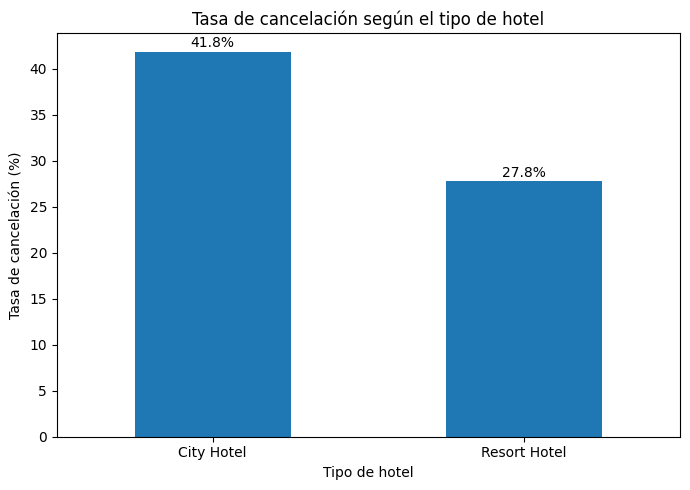

In [115]:
# Calculo la tasa de cancelación para cada tipo de hotel.
tasa_cancelacion_hotel = (
    df_raw.groupby("hotel")["is_canceled"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

display(tasa_cancelacion_hotel)


# Represento gráficamente la tasa de cancelación por tipo de hotel.
plt.figure(figsize=(7, 5))

ax = tasa_cancelacion_hotel.plot(kind="bar")

plt.title("Tasa de cancelación según el tipo de hotel")
plt.xlabel("Tipo de hotel")
plt.ylabel("Tasa de cancelación (%)")
plt.xticks(rotation=0)

# Muestro el valor de cada barra.
for i, valor in enumerate(tasa_cancelacion_hotel):
    ax.text(i, valor + 0.5, f"{valor:.1f}%", ha="center")

plt.tight_layout()
plt.show()

La tasa de cancelación presenta diferencias según el tipo de hotel. En las reservas del City Hotel se observa una tasa de cancelación del 41,78 %, frente al 27,76 % registrado en el Resort Hotel. Por tanto, dentro de este conjunto de datos, el tipo de hotel parece estar relacionado con el comportamiento de cancelación.

Desde el punto de vista de negocio, esta diferencia puede ser relevante para establecer estrategias de prevención de cancelaciones diferenciadas según el establecimiento. No obstante, este análisis únicamente muestra una asociación y no permite determinar por sí solo las causas de esta diferencia.

### 2.2.2. Cancelación según el mes de llegada

**Pregunta de negocio:**

¿Hay meses del año en los que las reservas presentan una mayor tasa de cancelación?

arrival_date_month
January     30.5016
February    33.4451
March       32.2277
April       40.7835
May         39.7029
June        41.4860
July        37.4644
August      37.7823
September   39.1905
October     38.0910
November    31.3100
December    35.0348
Name: is_canceled, dtype: float64

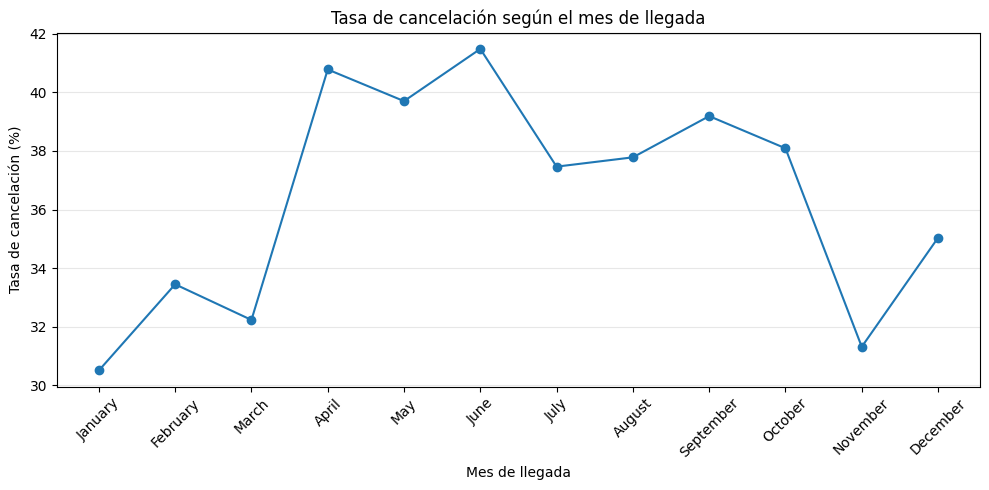

In [116]:
# Defino el orden natural de los meses.
orden_meses = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

# Calculo la tasa de cancelación por mes de llegada.
tasa_cancelacion_mes = (
    df_raw.groupby("arrival_date_month")["is_canceled"]
      .mean()
      .mul(100)
      .reindex(orden_meses)
)

display(tasa_cancelacion_mes)

# Represento la evolución de la tasa de cancelación a lo largo del año.
plt.figure(figsize=(10, 5))

plt.plot(
    tasa_cancelacion_mes.index,
    tasa_cancelacion_mes.values,
    marker="o"
)

plt.title("Tasa de cancelación según el mes de llegada")
plt.xlabel("Mes de llegada")
plt.ylabel("Tasa de cancelación (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

La tasa de cancelación varía según el mes de llegada. Los valores más elevados se observan en junio (41,48 %), abril (40,78 %) y mayo (39,70 %), mientras que enero presenta la tasa más baja (30,50 %). En conjunto, los resultados muestran diferencias entre los distintos periodos del año, lo que sugiere la existencia de un componente estacional en el comportamiento de las cancelaciones.

Desde una perspectiva de negocio, esta variación puede ser útil para anticipar periodos en los que resulte conveniente realizar un seguimiento más específico de las reservas. Sin embargo, las diferencias observadas representan una asociación y pueden estar relacionadas también con otras características de las reservas.

### 2.2.3. Cancelación según el canal de distribución

**Pregunta de negocio:**

¿El canal utilizado para realizar la reserva está relacionado con una mayor o menor tasa de cancelación?

distribution_channel
Undefined   80.0000
TA/TO       41.0598
Corporate   22.0568
GDS         19.1710
Direct      17.4868
Name: is_canceled, dtype: float64

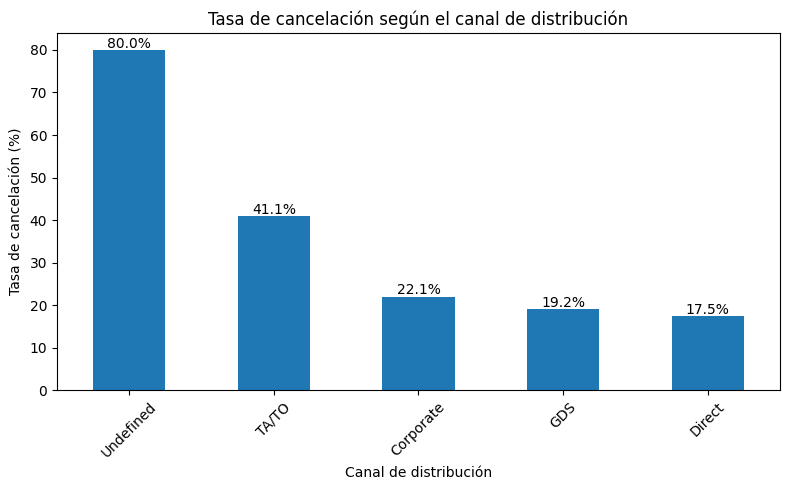

In [117]:
# Calculo la tasa de cancelación para cada canal de distribución.
tasa_cancelacion_canal = (
    df_raw.groupby("distribution_channel")["is_canceled"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

display(tasa_cancelacion_canal)

# Represento la tasa de cancelación según el canal de distribución.
plt.figure(figsize=(8, 5))

ax = tasa_cancelacion_canal.plot(kind="bar")

plt.title("Tasa de cancelación según el canal de distribución")
plt.xlabel("Canal de distribución")
plt.ylabel("Tasa de cancelación (%)")
plt.xticks(rotation=45)

for i, valor in enumerate(tasa_cancelacion_canal):
    ax.text(i, valor + 0.5, f"{valor:.1f}%", ha="center")

plt.tight_layout()
plt.show()

In [118]:
# Compruebo cuántas reservas pertenecen a cada canal de distribución.
reservas_por_canal = (
    df_raw["distribution_channel"]
    .value_counts()
)

display(reservas_por_canal)

# Comparo el número de reservas y la tasa de cancelación por canal.
resumen_canal = df_raw.groupby("distribution_channel")["is_canceled"].agg(
    reservas="count",
    cancelaciones="sum",
    tasa_cancelacion="mean"
)

resumen_canal["tasa_cancelacion"] = resumen_canal["tasa_cancelacion"] * 100

display(resumen_canal.sort_values("tasa_cancelacion", ascending=False))

distribution_channel
TA/TO        97750
Direct       14611
Corporate     6651
GDS            193
Undefined        5
Name: count, dtype: int64

,reservas,cancelaciones,tasa_cancelacion
distribution_channel,,,
Undefined,5,4,80.0000
TA/TO,97750,40136,41.0598
Corporate,6651,1467,22.0568
GDS,193,37,19.1710
Direct,14611,2555,17.4868


La tasa de cancelación presenta diferencias según el canal de distribución. El canal TA/TO concentra la mayor parte de las reservas, con 97.750 registros, y presenta una tasa de cancelación del 41,05 %. Le siguen los canales Corporate (22,05 %), GDS (19,17 %) y Direct (17,48 %).

La categoría `Undefined` presenta una tasa del 80 %, pero únicamente contiene cinco reservas, por lo que este porcentaje no resulta representativo y no se utilizará para extraer conclusiones generales. Los resultados sugieren que el canal de distribución puede aportar información relevante para anticipar el comportamiento de cancelación y, por tanto, se tendrá en cuenta durante el modelado.

### 2.2.4. Relación entre antelación de la reserva y cancelación

**Pregunta de negocio:**

¿Las reservas realizadas con mayor antelación presentan una mayor tasa de cancelación?

lead_time_group
0-7 días           9.6002
8-30 días         27.8860
31-90 días        37.7290
91-180 días       44.7350
181-365 días      55.4565
Más de 365 días   67.6517
Name: is_canceled, dtype: float64

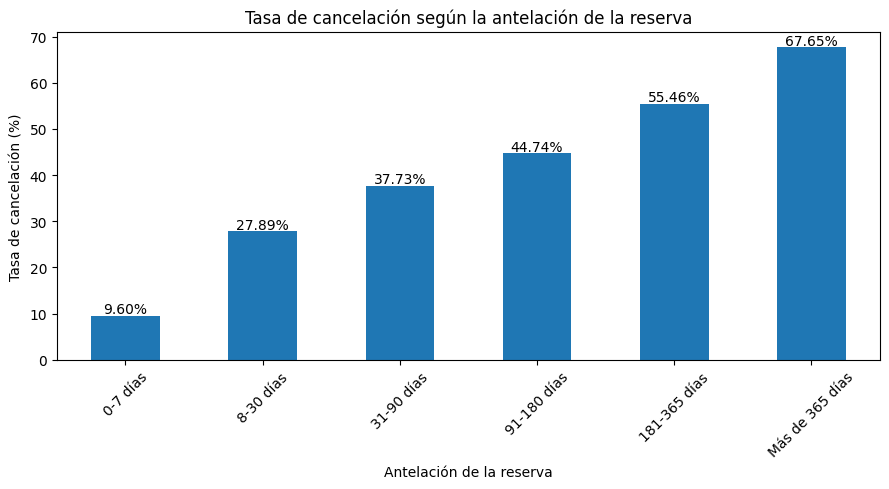

In [119]:
# Creo grupos de antelación para facilitar el análisis.
bins_lead_time = [0, 7, 30, 90, 180, 365, float("inf")]
labels_lead_time = [
    "0-7 días",
    "8-30 días",
    "31-90 días",
    "91-180 días",
    "181-365 días",
    "Más de 365 días"
]

df_raw["lead_time_group"] = pd.cut(
    df_raw["lead_time"],
    bins=bins_lead_time,
    labels=labels_lead_time,
    include_lowest=True
)

# Calculo la tasa de cancelación para cada intervalo.
tasa_cancelacion_lead_time = (
    df_raw.groupby("lead_time_group", observed=False)["is_canceled"]
      .mean()
      .mul(100)
)

display(tasa_cancelacion_lead_time)

# Represento la tasa de cancelación según la antelación de la reserva.
plt.figure(figsize=(9, 5))

ax = tasa_cancelacion_lead_time.plot(kind="bar")

plt.title("Tasa de cancelación según la antelación de la reserva")
plt.xlabel("Antelación de la reserva")
plt.ylabel("Tasa de cancelación (%)")
plt.xticks(rotation=45)

for i, valor in enumerate(tasa_cancelacion_lead_time):
    ax.text(i, valor + 0.5, f"{valor:.2f}%", ha="center")

plt.tight_layout()
plt.show()

La tasa de cancelación aumenta de forma progresiva a medida que aumenta la antelación de la reserva. Las reservas realizadas con una antelación de entre 0 y 7 días presentan una tasa de cancelación del 9,60 %, mientras que aquellas realizadas con más de 365 días de antelación alcanzan el 67,65 %.

Este resultado muestra una relación clara entre `lead_time` y la cancelación y resulta especialmente relevante para el objetivo del proyecto, ya que la antelación de la reserva es una característica disponible en el momento en que se realiza la reserva. Por tanto, puede proporcionar información útil para identificar anticipadamente reservas con un mayor riesgo de cancelación.

### 2.2.5. Precio medio diario y cancelación

**Pregunta de negocio:**

¿Existe una diferencia en el precio medio diario (adr) entre las reservas canceladas y las que no se cancelan?

is_canceled
0   100.1692
1   105.0237
Name: adr, dtype: float64

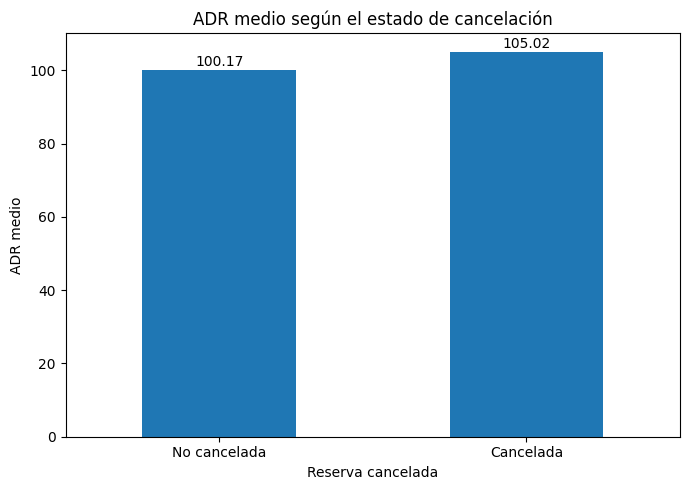

In [120]:
# Calculo el ADR medio según si la reserva fue cancelada o no.
adr_cancelacion = (
    df_raw.groupby("is_canceled")["adr"]
      .mean()
)

display(adr_cancelacion)

# Represento el ADR medio según el resultado de la reserva.
plt.figure(figsize=(7, 5))

ax = adr_cancelacion.plot(kind="bar")

plt.title("ADR medio según el estado de cancelación")
plt.xlabel("Reserva cancelada")
plt.ylabel("ADR medio")
plt.xticks(
    ticks=[0, 1],
    labels=["No cancelada", "Cancelada"],
    rotation=0
)

for i, valor in enumerate(adr_cancelacion):
    ax.text(i, valor + 1, f"{valor:.2f}", ha="center")

plt.tight_layout()
plt.show()

El ADR medio presenta una diferencia entre las reservas canceladas y las no canceladas. Las reservas que no fueron canceladas presentan un ADR medio de 100,17, mientras que las canceladas alcanzan un valor medio de 105,02. Por tanto, en este conjunto de datos, las reservas canceladas presentan un precio medio diario ligeramente superior.

La diferencia observada es moderada y la comparación de medias no permite determinar por sí sola si el precio está relacionado con la cancelación. Por ello, el ADR se mantendrá como posible variable explicativa y será el modelo el que permita valorar conjuntamente su utilidad junto con el resto de características de la reserva.

---
## 2.5 Tratamiento de nulos

Antes de construir features hay que decidir qué hacer con cada variable que tiene nulos.
La decisión no es técnica — es de negocio: ¿qué significa un nulo en este contexto?

### 2.5.1 Variable `children`

**Objetivo**: comprobar qué características tienen las pocas reservas en las que no se ha registrado el número de niños antes de decidir cómo completar el dato.

In [121]:
# Reviso las reservas que tienen el número de niños sin informar.
display(
    df_raw[df_raw["children"].isna()][
        ["adults", "children", "babies", "hotel", "is_canceled"]
    ]
)

,adults,children,babies,hotel,is_canceled
40600,2,NaN,0,City Hotel,1
40667,2,NaN,0,City Hotel,1
40679,3,NaN,0,City Hotel,1
41160,2,NaN,0,City Hotel,1


Los cuatro registros tienen 2 o 3 adultos y ningún bebé, pero no podemos saber a partir de estas variables si realmente había niños o simplemente no se registró el dato. Como solo afecta a 4 registros, no merece la pena eliminar esas reservas.

**Decisión**: sustituir los valores ausentes por la mediana de `children`, evitando asumir que un valor ausente equivale necesariamente a cero.

In [122]:
# Obtengo la mediana de children para utilizarla en la imputación.
mediana_children = df_raw["children"].median()

print(f"Mediana de children: {mediana_children}")

# Completo los valores ausentes de children utilizando la mediana.
df_raw["children"] = df_raw["children"].fillna(mediana_children)

# Mantengo children como una variable entera al representar un recuento.
df_raw["children"] = df_raw["children"].astype(int)

Mediana de children: 0.0


### 2.5.2 Variable `country`

**Objetivo**: comprobar si los valores ausentes de país presentan alguna característica común y valorar si es preferible conservar estas reservas identificándolas como desconocidas.

In [123]:
# Reviso las reservas que no tienen información sobre el país.
display(
    df_raw[df_raw["country"].isna()][
        ["country", "hotel", "market_segment", "distribution_channel", "is_canceled"]
    ].head(20)
)

,country,hotel,market_segment,distribution_channel,is_canceled
30,NaN,Resort Hotel,Direct,Direct,0
7092,NaN,Resort Hotel,Corporate,Corporate,1
7860,NaN,Resort Hotel,Direct,Direct,1
8779,NaN,Resort Hotel,Corporate,Corporate,1
9610,NaN,Resort Hotel,Corporate,Corporate,1
9612,NaN,Resort Hotel,Corporate,Corporate,1
11262,NaN,Resort Hotel,Offline TA/TO,TA/TO,1
11263,NaN,Resort Hotel,Offline TA/TO,TA/TO,1
11264,NaN,Resort Hotel,Offline TA/TO,TA/TO,1
11265,NaN,Resort Hotel,Offline TA/TO,TA/TO,1


Los resultados muestran que los 20 primeros casos pertenecen a diferentes combinaciones de `market_segment` y `distribution_channel`, por lo que no aparece un patrón único que permita deducir el país.

Como únicamente hay 488 registros (0,41 %) sin país, eliminarlos supondría perder información de reservas por una cantidad muy pequeña de datos faltantes. Es preferible conservarlas y representar explícitamente que el país es desconocido.

**Decisión**: sustituir los nulos por una categoría `"Unknown"`.

In [124]:
# Represento como "Unknown" las reservas cuyo país no está informado.
df_raw["country"] = df_raw["country"].fillna("Unknown")

### 2.5.3 Variable `agent`

**Objetivo**: analizar si los valores ausentes en `agent` pueden representar reservas sin agencia asociada o simplemente información no disponible.

In [125]:
# Reviso las reservas que no tienen una agencia registrada.
display(
    df_raw[df_raw["agent"].isna()][
        ["agent", "market_segment", "distribution_channel", "hotel", "is_canceled"]
    ].head(20)
)

,agent,market_segment,distribution_channel,hotel,is_canceled
0,NaN,Direct,Direct,Resort Hotel,0
1,NaN,Direct,Direct,Resort Hotel,0
2,NaN,Direct,Direct,Resort Hotel,0
6,NaN,Direct,Direct,Resort Hotel,0
18,NaN,Corporate,Corporate,Resort Hotel,0
30,NaN,Direct,Direct,Resort Hotel,0
32,NaN,Direct,Direct,Resort Hotel,1
42,NaN,Direct,Direct,Resort Hotel,0
55,NaN,Direct,Direct,Resort Hotel,0
56,NaN,Direct,Direct,Resort Hotel,0


En los registros revisados predominan las reservas con `market_segment = Direct` y `distribution_channel = Direct`, aunque también aparecen algunos casos `Corporate` y `Complementary`. Por tanto, no podemos asumir que todos los valores ausentes correspondan exclusivamente a reservas directas.

Como `agent` es un identificador de agencia y el hecho de que no exista un valor registrado constituye información en sí misma, podemos conservar esa situación como una categoría independiente.

**Decisión**: tratar la ausencia como `"Unknown"` en lugar de asignar un identificador numérico artificial.

In [126]:
# Convierto la ausencia de agencia en una categoría explícita.
df_raw["agent"] = df_raw["agent"].fillna("Unknown").astype(str)

### 2.5.4 Variable `company`

**Objetivo**: comprobar qué características tienen las reservas sin empresa registrada antes de decidir si esta variable aporta suficiente información para conservarla.

In [127]:
# Reviso algunas características de las reservas sin empresa registrada.
display(
    df_raw[df_raw["company"].isna()][
        ["company", "market_segment", "distribution_channel", "customer_type", "hotel", "is_canceled"]
    ].head(20)
)

,company,market_segment,distribution_channel,customer_type,hotel,is_canceled
0,NaN,Direct,Direct,Transient,Resort Hotel,0
1,NaN,Direct,Direct,Transient,Resort Hotel,0
2,NaN,Direct,Direct,Transient,Resort Hotel,0
3,NaN,Corporate,Corporate,Transient,Resort Hotel,0
4,NaN,Online TA,TA/TO,Transient,Resort Hotel,0
5,NaN,Online TA,TA/TO,Transient,Resort Hotel,0
6,NaN,Direct,Direct,Transient,Resort Hotel,0
7,NaN,Direct,Direct,Transient,Resort Hotel,0
8,NaN,Online TA,TA/TO,Transient,Resort Hotel,1
9,NaN,Offline TA/TO,TA/TO,Transient,Resort Hotel,1


La revisión muestra que la ausencia de `company` aparece en distintos segmentos, canales y tipos de cliente. No podemos asignar una empresa concreta a partir del resto de variables.

Además, 94,31 % de los registros no contienen información en esta variable, por lo que convertir todos esos valores en una categoría `"Unknown"` haría que prácticamente toda la variable perteneciera a una misma categoría y mantendría una variable con una cantidad muy elevada de información ausente.

**Decisión**: excluir `company` del modelado por su elevado porcentaje de valores ausentes.

In [128]:
# Elimino company debido a su elevado porcentaje de valores ausentes.
df_raw = df_raw.drop(columns=["company"])

### 2.5.5 Comprobación final

**Objetivo**: verificar que las decisiones tomadas han eliminado los valores ausentes que impedían trabajar con las variables seleccionadas para el modelado.

In [129]:
# Compruebo los valores nulos restantes después del tratamiento.
nulos_restantes = df_raw.isnull().sum()

display(
    nulos_restantes[nulos_restantes > 0]
)

Series([], dtype: int64)

El tratamiento de los valores ausentes se ha realizado teniendo en cuenta tanto su frecuencia como el significado de cada variable. Los cuatro valores ausentes de `children` se han sustituido por la mediana, cuyo valor es 0, y posteriormente la variable se ha convertido a tipo entero. En `country` y `agent` se ha utilizado la categoría `Unknown` para conservar las reservas sin eliminar observaciones. En el caso de `company`, se ha optado por eliminar la variable debido a que el 94,31 % de sus valores estaban ausentes y no se dispone de información suficiente para realizar una imputación fiable.

Tras aplicar estos tratamientos, la comprobación final muestra que no quedan valores nulos en el conjunto de datos.

---
## 3. Feature Engineering

Cada variable nueva se justifica desde la perspectiva de negocio.  
**Regla:** si no puedes explicar por qué esta variable debería ser predictiva, no la incluyas.

### 3.1. Número total de huéspedes

**Objetivo**: combinar adultos, niños y bebés para representar el tamaño total del grupo de una reserva en una única variable.

In [130]:
# Creo una variable que representa el número total de huéspedes de la reserva.
df_raw["total_guests"] = df_raw["adults"] + df_raw["children"] + df_raw["babies"]

display(df_raw[["adults", "children", "babies", "total_guests"]].head())

,adults,children,babies,total_guests
0,2,0,0,2
1,2,0,0,2
2,1,0,0,1
3,1,0,0,1
4,2,0,0,2


La variable `total_guests` permite resumir en una única medida el tamaño de la reserva, integrando adultos, niños y bebés. Desde el punto de vista de negocio, el número total de huéspedes puede ayudar a diferenciar reservas individuales o de pocas personas de aquellas asociadas a grupos más numerosos.

### 3.2. Número total de noches

**Objetivo**: obtener la duración completa de cada estancia sumando las noches de entre semana y de fin de semana.

In [131]:
# Calculo el número total de noches de cada reserva.
df_raw["total_nights"] = (
    df_raw["stays_in_weekend_nights"] +
    df_raw["stays_in_week_nights"]
)

display(df_raw[[
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "total_nights"
]].head())

,stays_in_weekend_nights,stays_in_week_nights,total_nights
0,0,0,0
1,0,0,0
2,0,1,1
3,0,1,1
4,0,2,2


La variable `total_nights` permite conocer la duración completa de la estancia, combinando las noches de entre semana y de fin de semana. Esta información puede ser relevante para analizar si la duración prevista de la estancia está relacionada con la probabilidad de cancelación.

### 3.3. Comprobación de la duración de las estancias

**Objetivo**: revisar la distribución de `total_nights` antes de decidir si resulta útil crear una variable que identifique las estancias largas.

In [132]:
# Reviso la distribución de la duración total de las estancias.
display(df_raw["total_nights"].describe())

count   119210.0000
mean         3.4262
std          2.5407
min          0.0000
25%          2.0000
50%          3.0000
75%          4.0000
max         69.0000
Name: total_nights, dtype: float64

La distribución de `total_nights` muestra una mediana de 3 noches y un tercer cuartil de 4 noches. A partir de estos valores se considera útil distinguir las reservas de más de 4 noches para identificar las estancias de mayor duración.

### 3.4. Indicador de estancia larga

**Objetivo**: identificar las reservas cuya duración supera la estancia habitual del conjunto de datos.

In [133]:
# Creo un indicador para identificar las estancias de más de 4 noches.
df_raw["is_long_stay"] = (df_raw["total_nights"] > 4).astype(int)

display(df_raw[[
    "total_nights",
    "is_long_stay"
]].head())

,total_nights,is_long_stay
0,0,0
1,0,0
2,1,0
3,1,0
4,2,0


La variable `is_long_stay` permite identificar mediante un indicador binario las reservas cuya duración supera las 4 noches. Esta transformación facilita que el modelo pueda utilizar de forma directa la información sobre las estancias de mayor duración.

### 3.5. Comprobación de las nuevas variables

**Objetivo**: comprobar que las variables creadas se han calculado correctamente y revisar su distribución antes de utilizarlas en el modelado.

In [134]:
# Compruebo las nuevas variables creadas y su distribución.
display(df_raw[[
    "total_guests",
    "total_nights",
    "is_long_stay"
]].describe())

,total_guests,total_nights,is_long_stay
count,119210.0000,119210.0000,119210.0000
mean,1.9712,3.4262,0.2138
std,0.7189,2.5407,0.4100
min,1.0000,0.0000,0.0000
25%,2.0000,2.0000,0.0000
50%,2.0000,3.0000,0.0000
75%,2.0000,4.0000,0.0000
max,55.0000,69.0000,1.0000


La comprobación confirma que las tres variables creadas presentan información para las 119.210 reservas y no contienen valores ausentes. Además, `is_long_stay` toma únicamente valores 0 y 1, mientras que `total_guests` y `total_nights` mantienen valores coherentes con las variables utilizadas para su cálculo.

### 3.6. Eliminación de variables auxiliares

La variable `lead_time_group` se creó únicamente para facilitar el análisis exploratorio de la relación entre la antelación de la reserva y la cancelación. Al no formar parte de las variables definitivas de modelado, se elimina antes de continuar con el entrenamiento.

In [135]:
# Elimino la variable creada únicamente para el análisis exploratorio.
df_raw = df_raw.drop(columns=["lead_time_group"])

---
## 4. Train y Test

La separación entre entrenamiento y prueba se realiza respetando el orden temporal de las reservas. Se utiliza el 80 % inicial de las observaciones para entrenar los modelos y el 20 % posterior para evaluar su comportamiento sobre un periodo posterior.

Esta estrategia resulta adecuada para el objetivo del proyecto, ya que la predicción pretende realizarse en el momento de la reserva y, por tanto, es importante evitar que el entrenamiento utilice información procedente de periodos posteriores al conjunto de evaluación.

### 4.1 Separación de la variable objetivo

La variable `is_canceled` será la variable objetivo que el modelo deberá predecir. El resto de variables se utilizarán como características de entrada.

In [136]:
# Separo la variable objetivo del resto de variables.
X = df_raw.drop(columns=["is_canceled"])
y = df_raw["is_canceled"]

print(f"Variables predictoras: {X.shape[1]}")
print(f"Registros: {X.shape[0]}")

Variables predictoras: 30
Registros: 119210


El recuento correcto es:

- 32 variables originales.

- −3 por `reservation_status`, `reservation_status_date` y `assigned_room_type` → 29.

- −1 por `company` → 28.

- +3 nuevas variables (`total_guests`, `total_nights`, `is_long_stay`) → 31.

- −1 por `is_canceled`, que es la variable objetivo → 30 predictoras.

In [137]:
# Compruebo qué variables se utilizarán como predictoras.
print(X.columns.tolist())

['hotel', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'booking_changes', 'deposit_type', 'agent', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_guests', 'total_nights', 'is_long_stay']


La variable `is_canceled` se establece como variable objetivo, mientras que las 30 variables restantes se utilizan como variables predictoras. La lista obtenida confirma que se han mantenido las variables seleccionadas para el modelado y que las variables identificadas previamente como posibles fuentes de *data leakage* no forman parte del conjunto de entrada.


### 4.2 División temporal de los datos

Dado que las reservas están asociadas a fechas de llegada y el objetivo es realizar predicciones en un contexto real, se utiliza una división temporal. Los registros correspondientes a los periodos más antiguos se emplean para entrenar el modelo, mientras que los periodos posteriores se reservan para su evaluación.

In [138]:
# Creo una fecha de llegada combinando año, mes y día.
meses = {
    "January": 1,
    "February": 2,
    "March": 3,
    "April": 4,
    "May": 5,
    "June": 6,
    "July": 7,
    "August": 8,
    "September": 9,
    "October": 10,
    "November": 11,
    "December": 12
}

fecha_llegada = pd.to_datetime(
    df_raw["arrival_date_year"].astype(str) + "-" +
    df_raw["arrival_date_month"].map(meses).astype(str) + "-" +
    df_raw["arrival_date_day_of_month"].astype(str)
)

display(fecha_llegada.head())

0   2015-07-01
1   2015-07-01
2   2015-07-01
3   2015-07-01
4   2015-07-01
dtype: datetime64[ns]

Al construir una nueva variable de tipo fecha combinando el año, mes y día de llegada de cada reserva, se puede ordenar temporalmente las observaciones y realizar posteriormente una separación entre reservas utilizadas para el entrenamiento y reservas posteriores utilizadas para la evaluación.

### 4.3 Comprobación de la distribución temporal

Antes de realizar la división definitiva, se comprueba cómo están distribuidas las reservas entre los diferentes años disponibles. Esta revisión permite establecer el punto de corte temporal de forma coherente con los datos disponibles.

In [139]:
# Ordeno los registros cronológicamente antes de realizar la separación.
orden_temporal = fecha_llegada.sort_values().index

X = X.loc[orden_temporal].reset_index(drop=True)
y = y.loc[orden_temporal].reset_index(drop=True)
fecha_llegada = fecha_llegada.loc[orden_temporal].reset_index(drop=True)

display(fecha_llegada.head())
display(fecha_llegada.tail())

0   2015-07-01
1   2015-07-01
2   2015-07-01
3   2015-07-01
4   2015-07-01
dtype: datetime64[ns]

119205   2017-08-31
119206   2017-08-31
119207   2017-08-31
119208   2017-08-31
119209   2017-08-31
dtype: datetime64[ns]

La variable creada muestra que las reservas abarcan desde el 1 de julio de 2015 hasta el 31 de agosto de 2017. Este intervalo permite realizar una división temporal, utilizando información de periodos anteriores para entrenar el modelo y reservando un periodo posterior para evaluar su comportamiento.

### 4.4 Creación de Train y Test

Una vez establecido el criterio temporal, se generan los conjuntos `X_train`, `X_test`, `y_train` e `y_test`. El conjunto de entrenamiento contiene las características y objetivos correspondientes al periodo utilizado para aprender, mientras que el conjunto de test contiene únicamente información posterior.

In [140]:
# Separo el 80 % inicial para entrenamiento y el 20 % final para test.
punto_corte = int(len(X) * 0.80)

X_train = X.iloc[:punto_corte].copy()
X_test = X.iloc[punto_corte:].copy()

y_train = y.iloc[:punto_corte].copy()
y_test = y.iloc[punto_corte:].copy()

print(f"Train: {X_train.shape[0]:,} registros")
print(f"Test: {X_test.shape[0]:,} registros")

Train: 95,368 registros
Test: 23,842 registros


Se divide el conjunto de datos utilizando un criterio temporal, destinando aproximadamente el 80 % de las observaciones al entrenamiento y el 20 % restante a la evaluación. De esta forma, el modelo aprende utilizando reservas de periodos anteriores y se evalúa posteriormente sobre reservas de un periodo más reciente.

### 4.5 Comprobación de los tamaños de Train y Test

Finalmente, se comprueba el número de registros y variables de cada conjunto para verificar que la división se ha realizado correctamente.

In [141]:
# Compruebo que las fechas de Train y Test respetan el orden temporal.
print(f"Fecha inicial Train: {fecha_llegada.iloc[0].date()}")
print(f"Fecha final Train: {fecha_llegada.iloc[punto_corte - 1].date()}")

print(f"Fecha inicial Test: {fecha_llegada.iloc[punto_corte].date()}")
print(f"Fecha final Test: {fecha_llegada.iloc[-1].date()}")

Fecha inicial Train: 2015-07-01
Fecha final Train: 2017-04-22
Fecha inicial Test: 2017-04-22
Fecha final Test: 2017-08-31


In [142]:
# Compruebo la distribución de cancelaciones en Train y Test.
print("Distribución en Train:")
display(y_train.value_counts(normalize=True).mul(100))

print("Distribución en Test:")
display(y_test.value_counts(normalize=True).mul(100))

Distribución en Train:


is_canceled
0   63.9019
1   36.0981
Name: proportion, dtype: float64

Distribución en Test:


is_canceled
0   59.0093
1   40.9907
Name: proportion, dtype: float64

La comprobación confirma que el conjunto de entrenamiento contiene reservas desde julio de 2015 hasta abril de 2017, mientras que el conjunto de test corresponde al periodo posterior hasta agosto de 2017. Por tanto, la separación respeta el orden temporal de las observaciones.

La distribución de la variable objetivo presenta un 36,09 % de cancelaciones en Train y un 40,99 % en Test. Aunque existe una diferencia entre ambos conjuntos, no se realiza un reajuste de las proporciones, ya que la división temporal busca mantener las características reales de cada periodo y evaluar el modelo sobre datos posteriores al periodo utilizado para su entrenamiento.

---
## 5. Preprocesado

En esta fase se preparan las variables para que puedan ser utilizadas por los modelos de Machine Learning. Como el conjunto contiene variables numéricas y categóricas, será necesario aplicar un tratamiento diferente según el tipo de variable.

### 5.1. Identificación de variables numéricas y categóricas

**Objetivo**: separar las variables predictoras según su tipo para poder aplicar a cada grupo el tratamiento adecuado.

In [143]:
# Identifico las variables numéricas y categóricas.
variables_numericas = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
variables_categoricas = X.select_dtypes(include=["object"]).columns.tolist()

print("Variables numéricas:")
print(variables_numericas)

print("\nVariables categóricas:")
print(variables_categoricas)

Variables numéricas:
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_guests', 'total_nights', 'is_long_stay']

Variables categóricas:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type']


Las 30 variables predictoras se distribuyen entre 20 variables numéricas y 10 variables categóricas. La clasificación permite aplicar posteriormente un tratamiento específico a cada tipo de variable antes de utilizar los datos en los modelos.

### 5.2. Selección del preprocesado para variables numéricas

Para las variables numéricas utilizaremos `StandardScaler`, que transforma las variables para que tengan una media cercana a 0 y una desviación estándar cercana a 1.

In [144]:
# Defino el tratamiento para las variables numéricas.
preprocesado_numericas = StandardScaler()

Las variables numéricas se estandarizarán mediante `StandardScaler` para situarlas en una escala comparable. Esta transformación resulta especialmente útil para modelos sensibles a la escala de las variables y permite evitar que aquellas con valores numéricamente mayores tengan una influencia desproporcionada.

### 5.3. Preprocesado de variables categóricas

Las variables categóricas contienen texto y los modelos de Machine Learning necesitan recibir valores numéricos. Por ello, usaré `OneHotEncoder`, que transforma cada categoría en una variable binaria independiente.

In [145]:
preprocesado_categoricas = OneHotEncoder(handle_unknown="ignore")

Las variables categóricas se transforman mediante `OneHotEncoder` para convertir sus categorías en variables numéricas que puedan ser utilizadas por los modelos. Se utiliza `handle_unknown="ignore"` para poder procesar categorías que aparezcan en el conjunto de test y que no estuvieran presentes durante el entrenamiento.

### 5.4 Construcción del preprocesador

Ahora junto ambos tratamientos mediante `ColumnTransformer`.

In [146]:
preprocesador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), variables_numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), variables_categoricas)
    ]
)

Se utiliza `ColumnTransformer` para aplicar de forma conjunta el tratamiento correspondiente a cada tipo de variable. De esta manera, el proceso de transformación queda centralizado y puede integrarse posteriormente con los modelos mediante un `Pipeline`, evitando repetir manualmente las mismas operaciones.

### 5.5. Aplicación del preprocesador sobre Train y Test

El preprocesador debe aprender sus parámetros únicamente a partir de Train. Después se utiliza esa misma transformación para convertir Test.

In [147]:
# Ajusto el preprocesador únicamente con los datos de entrenamiento.
X_train_preprocesado = preprocesador.fit_transform(X_train)

# Aplico la misma transformación al conjunto de test.
X_test_preprocesado = preprocesador.transform(X_test)

print(f"Train preprocesado: {X_train_preprocesado.shape}")
print(f"Test preprocesado: {X_test_preprocesado.shape}")

Train preprocesado: (95368, 547)
Test preprocesado: (23842, 547)


Tras aplicar el preprocesado, Train conserva sus 95.368 registros y Test sus 23.842 registros. Las variables originales se transforman en 547 variables, debido principalmente a la expansión de las variables categóricas mediante One-Hot Encoding. El mismo conjunto de transformaciones se aplica a Train y Test, manteniendo una estructura de entrada compatible para los modelos posteriores.

---
## 6. Modelo Baseline — Regresión Logística

El baseline sirve como cota inferior: cualquier modelo más complejo debe superarlo de forma justificada.


### 6.1. Construcción del Pipeline

**Objetivo**: crear el modelo baseline combinando el preprocesado definido anteriormente con una Regresión Logística.

In [148]:
# Creo el pipeline del modelo baseline.
baseline = Pipeline([
    ("preprocesado", preprocesador),
    ("modelo", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

Se integra el preprocesado de las variables y la Regresión Logística dentro de un único `Pipeline`. De esta forma, las transformaciones necesarias se aplican de manera conjunta con el modelo y se mantiene un proceso reproducible para el entrenamiento y las predicciones.

### 6.2. Entrenamiento del modelo

**Objetivo**: entrenar la Regresión Logística utilizando únicamente el conjunto de entrenamiento.

In [149]:
# Entreno el modelo baseline con los datos de entrenamiento.
baseline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesado', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['hotel','lead_time','arrival_date_year',...,'total_guests','total_nights', 'is_long_stay']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder=

La Regresión Logística se entrena utilizando exclusivamente el conjunto de entrenamiento mediante el `Pipeline` definido anteriormente. Durante este proceso, las 20 variables numéricas se estandarizan y las variables categóricas se transforman mediante One-Hot Encoding, generando 547 variables de entrada para el modelo.

El diagrama del `Pipeline` permite comprobar que el preprocesado y el modelo forman un único flujo, de modo que las transformaciones se aplican antes de entrenar la Regresión Logística y utilizando únicamente la información disponible en el conjunto de entrenamiento.

### 6.3. Predicciones sobre el conjunto de test

**Objetivo**: obtener las predicciones del modelo sobre datos que no se han utilizado durante el entrenamiento.

In [150]:
# Obtengo las predicciones sobre el conjunto de test.
y_pred_baseline = baseline.predict(X_test)

# Obtengo las probabilidades de pertenecer a la clase de cancelación.
y_prob_baseline = baseline.predict_proba(X_test)[:, 1]

Una vez entrenado el modelo, se realizan predicciones sobre el conjunto `Test`, que no ha participado en el entrenamiento. Se obtienen tanto las clases predichas como las probabilidades de cancelación, necesarias para evaluar el modelo mediante las diferentes métricas.

### 6.4. Evaluación del modelo

**Objetivo**: evaluar el comportamiento del baseline desde diferentes perspectivas, prestando especial atención a la capacidad para identificar las reservas que finalmente se cancelan.

In [151]:
accuracy_baseline = accuracy_score(y_test, y_pred_baseline)
precision_baseline = precision_score(y_test, y_pred_baseline)
recall_baseline = recall_score(y_test, y_pred_baseline)
f1_baseline = f1_score(y_test, y_pred_baseline)
roc_auc_baseline = roc_auc_score(y_test, y_prob_baseline)

print(f"Accuracy:  {accuracy_baseline:.4f}")
print(f"Precision: {precision_baseline:.4f}")
print(f"Recall:    {recall_baseline:.4f}")
print(f"F1-score:  {f1_baseline:.4f}")
print(f"ROC-AUC:   {roc_auc_baseline:.4f}")

Accuracy:  0.7860
Precision: 0.7234
Recall:    0.7739
F1-score:  0.7478
ROC-AUC:   0.8740


La Regresión Logística obtiene una accuracy de 0,7860, un precision de 0,7234 y un recall de 0,7739. El F1-score alcanza 0,7478 y el ROC-AUC 0,8740.

El modelo consigue identificar correctamente una parte importante de las reservas canceladas, como refleja el recall, mientras que el ROC-AUC proporciona una medida de su capacidad para distinguir entre reservas canceladas y no canceladas.

### 6.5. Matriz de confusión

**Objetivo**: comprobar cuántas reservas canceladas y no canceladas identifica correctamente el modelo y qué tipos de errores comete.

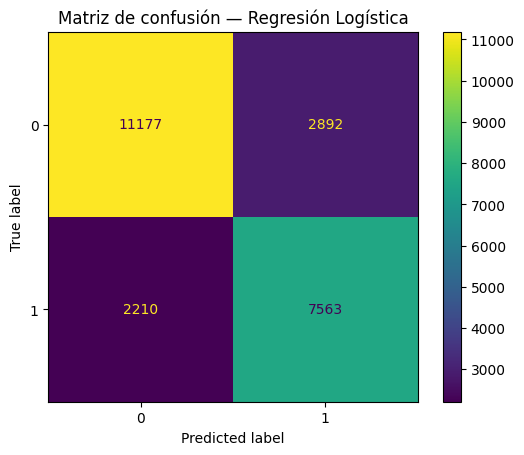

In [152]:
# Muestro la matriz de confusión del modelo baseline.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_baseline
)

plt.title("Matriz de confusión — Regresión Logística")
plt.show()

La matriz de confusión permite descomponer las predicciones del modelo en aciertos y errores según la clase real de cada reserva. Esta representación permite observar de forma directa cuántas cancelaciones son detectadas correctamente y cuántas pasan inadvertidas, además de los casos en los que se predice una cancelación que finalmente no se produce.

### 6.6. Curva ROC

**Objetivo**: complementar el valor numérico de ROC-AUC con una representación gráfica del comportamiento del modelo.

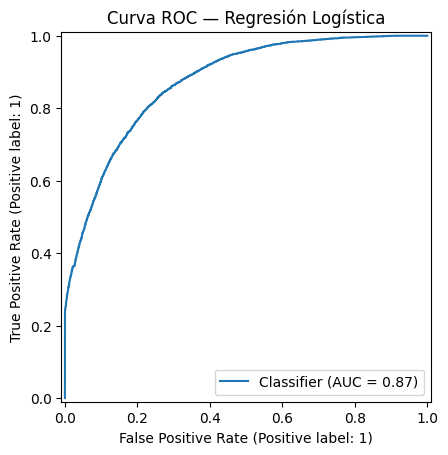

In [153]:
# Represento la curva ROC del modelo baseline.
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_baseline
)

plt.title("Curva ROC — Regresión Logística")
plt.show()

La curva ROC permite analizar el comportamiento del modelo para diferentes umbrales de clasificación. Su representación complementa el valor ROC-AUC obtenido anteriormente y permite visualizar la capacidad del modelo para diferenciar entre reservas canceladas y no canceladas.

### 6.7. Interpretación del baseline

La Regresión Logística alcanza una accuracy de 0,7860, identificando correctamente aproximadamente el 79 % de las reservas del conjunto de test. El precision es de 0,7234, mientras que el recall alcanza 0,7739, lo que indica que el modelo identifica correctamente una parte importante de las reservas que finalmente son canceladas.

El F1-score, con un valor de 0,7478, proporciona una medida conjunta del precision y el recall. Por su parte, el ROC-AUC alcanza 0,8740, mostrando una capacidad de discriminación elevada entre las reservas canceladas y no canceladas.

Estos resultados establecen la referencia para los modelos que se probarán a continuación. Los modelos posteriores deberán compararse utilizando las mismas métricas y sobre el mismo conjunto de test para determinar si aportan una mejora respecto a este baseline.


---
## 7. Modelos 

Una vez establecido el modelo baseline, se prueban diferentes algoritmos de clasificación para comprobar si otros enfoques permiten mejorar los resultados obtenidos con la Regresión Logística. Los modelos se entrenarán utilizando el mismo conjunto de entrenamiento y se evaluarán sobre el mismo conjunto de test.

La comparación se realizará mediante accuracy, precision, recall, F1-score y ROC-AUC, manteniendo las mismas métricas utilizadas para evaluar el baseline


### 7.1. Modelos seleccionados

Selecciono tres modelos adicionales para comparar diferentes enfoques de clasificación. Random Forest permite trabajar con múltiples árboles de decisión, mientras que Gradient Boosting y XGBoost utilizan métodos de boosting para construir modelos de forma secuencial.

La selección permite comparar la Regresión Logística, utilizada como referencia, con modelos basados en árboles y técnicas de ensamblado.


**Objetivo**: entrenar un modelo basado en múltiples árboles de decisión y evaluar si mejora el comportamiento del baseline.

### 7.2. Random Forest

In [154]:
# Creo el modelo Random Forest.
modelo_rf = Pipeline([
    ("preprocesado", preprocesador),
    ("modelo", RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Entreno el modelo.
modelo_rf.fit(X_train, y_train)

# Obtengo predicciones y probabilidades.
y_pred_rf = modelo_rf.predict(X_test)
y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

In [155]:
# Evaluo el modelo Random Forest con métricas de clasificación.
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-score:  {f1_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

Accuracy:  0.7855
Precision: 0.8370
Recall:    0.5919
F1-score:  0.6934
ROC-AUC:   0.8870


Random Forest obtiene una accuracy de 0,7855 y un ROC-AUC de 0,8870. Destaca por alcanzar el precision más elevado de los cuatro modelos, con un valor de 0,8370, aunque presenta un recall de 0,5919.

Esto significa que el modelo es más preciso cuando identifica una reserva como cancelada, pero detecta una proporción menor de las cancelaciones que finalmente se producen. Su F1-score es de 0,6934.

### 7.3. Gradient Boosting

In [156]:
# Creo el modelo Gradient Boosting.
modelo_gb = Pipeline([
    ("preprocesado", preprocesador),
    ("modelo", GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ))
])

# Entreno el modelo.
modelo_gb.fit(X_train, y_train)

# Obtengo predicciones y probabilidades.
y_pred_gb = modelo_gb.predict(X_test)
y_prob_gb = modelo_gb.predict_proba(X_test)[:, 1]

In [157]:
# Evaluo el modelo Gradient Boosting con métricas de clasificación.
accuracy_gb = accuracy_score(y_test, y_pred_gb)
precision_gb = precision_score(y_test, y_pred_gb)
recall_gb = recall_score(y_test, y_pred_gb)
f1_gb = f1_score(y_test, y_pred_gb)
roc_auc_gb = roc_auc_score(y_test, y_prob_gb)

print(f"Accuracy:  {accuracy_gb:.4f}")
print(f"Precision: {precision_gb:.4f}")
print(f"Recall:    {recall_gb:.4f}")
print(f"F1-score:  {f1_gb:.4f}")
print(f"ROC-AUC:   {roc_auc_gb:.4f}")

Accuracy:  0.7911
Precision: 0.8114
Recall:    0.6390
F1-score:  0.7149
ROC-AUC:   0.8870


Gradient Boosting alcanza una accuracy de 0,7911 y un ROC-AUC de 0,8870. Presenta un precision de 0,8114 y un recall de 0,6390, situándose entre los modelos evaluados en cuanto al equilibrio entre ambas métricas.

Su F1-score es de 0,7149. Los resultados muestran una capacidad de discriminación superior a la de la Regresión Logística según ROC-AUC, aunque el recall (0,6390) es inferior al obtenido por el baseline.

### 7.4. XGBoost

In [158]:
# Creo el modelo XGBoost.
modelo_xgb = Pipeline([
    ("preprocesado", preprocesador),
    ("modelo", XGBClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        eval_metric="logloss"
    ))
])

# Entreno el modelo.
modelo_xgb.fit(X_train, y_train)

# Obtengo predicciones y probabilidades.
y_pred_xgb = modelo_xgb.predict(X_test)
y_prob_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

In [159]:
# Evaluo el modelo XGBoost con métricas de clasificación.
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print(f"Accuracy:  {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall:    {recall_xgb:.4f}")
print(f"F1-score:  {f1_xgb:.4f}")
print(f"ROC-AUC:   {roc_auc_xgb:.4f}")

Accuracy:  0.8081
Precision: 0.7936
Recall:    0.7186
F1-score:  0.7543
ROC-AUC:   0.8989


XGBoost obtiene una accuracy de 0,8081, un precision de 0,7936 y un recall de 0,7186. Su F1-score alcanza 0,7543 y presenta el ROC-AUC más elevado de los modelos comparados, con un valor de 0,8989.

En este primer entrenamiento, XGBoost muestra una combinación equilibrada de las métricas consideradas y una capacidad de discriminación superior a la obtenida por los demás modelos evaluados mediante ROC-AUC.

### 7.5. Comparación inicial de modelos

Una vez ejecutados los tres modelos, reuno los resultados en una tabla.

In [160]:
resultados_modelos = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_baseline,
        accuracy_rf,
        accuracy_gb,
        accuracy_xgb
    ],
    "Precision": [
        precision_baseline,
        precision_rf,
        precision_gb,
        precision_xgb
    ],
    "Recall": [
        recall_baseline,
        recall_rf,
        recall_gb,
        recall_xgb
    ],
    "F1-score": [
        f1_baseline,
        f1_rf,
        f1_gb,
        f1_xgb
    ],
    "ROC-AUC": [
        roc_auc_baseline,
        roc_auc_rf,
        roc_auc_gb,
        roc_auc_xgb
    ]
})

display(resultados_modelos.round(4))

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Regresión Logística,0.7860,0.7234,0.7739,0.7478,0.8740
1,Random Forest,0.7855,0.8370,0.5919,0.6934,0.8870
2,Gradient Boosting,0.7911,0.8114,0.6390,0.7149,0.8870
3,XGBoost,0.8081,0.7936,0.7186,0.7543,0.8989


La comparación muestra diferencias entre los modelos según la métrica utilizada. XGBoost obtiene la mayor accuracy y el mayor ROC-AUC, mientras que Random Forest presenta el precision más elevado y la Regresión Logística obtiene el recall más alto.

Por tanto, los resultados muestran que no existe un único modelo que destaque simultáneamente en todas las métricas. Esta comparación inicial permite identificar diferentes comportamientos y servirá como punto de partida para la optimización de los modelos en el siguiente apartado.

### 7.6. Gestión del desbalanceo

Ninguno de los cuatro modelos entrenados hasta ahora corrige el desequilibrio entre reservas canceladas y no canceladas, así que en este apartado vuelvo a entrenar los mismos cuatro modelos, pero indicándoles que den más peso a la clase minoritaria durante el entrenamiento, para comprobar si esto mejora su capacidad de detectar cancelaciones sin empeorar demasiado el resto de métricas.

In [161]:
# Calculo el peso que debe recibir la clase minoritaria para XGBoost.
scale_pos_weight_valor = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Peso de la clase minoritaria para XGBoost: {scale_pos_weight_valor:.4f}")

# Regresión Logística con las clases balanceadas.
baseline_balanceado = Pipeline([
    ("preprocesado", preprocesador),
    ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
baseline_balanceado.fit(X_train, y_train)
y_pred_baseline_bal = baseline_balanceado.predict(X_test)
y_prob_baseline_bal = baseline_balanceado.predict_proba(X_test)[:, 1]

# Random Forest con las clases balanceadas.
modelo_rf_balanceado = Pipeline([
    ("preprocesado", preprocesador),
    ("modelo", RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight="balanced"
    ))
])
modelo_rf_balanceado.fit(X_train, y_train)
y_pred_rf_bal = modelo_rf_balanceado.predict(X_test)
y_prob_rf_bal = modelo_rf_balanceado.predict_proba(X_test)[:, 1]

# Gradient Boosting no admite class_weight, así que calculo el peso de cada fila manualmente.
pesos_muestra_train = compute_sample_weight(class_weight="balanced", y=y_train)

modelo_gb_balanceado = Pipeline([
    ("preprocesado", preprocesador),
    ("modelo", GradientBoostingClassifier(random_state=RANDOM_STATE))
])
modelo_gb_balanceado.fit(X_train, y_train, modelo__sample_weight=pesos_muestra_train)
y_pred_gb_bal = modelo_gb_balanceado.predict(X_test)
y_prob_gb_bal = modelo_gb_balanceado.predict_proba(X_test)[:, 1]

# XGBoost admite directamente el parámetro scale_pos_weight.
modelo_xgb_balanceado = Pipeline([
    ("preprocesado", preprocesador),
    ("modelo", XGBClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight_valor
    ))
])
modelo_xgb_balanceado.fit(X_train, y_train)
y_pred_xgb_bal = modelo_xgb_balanceado.predict(X_test)
y_prob_xgb_bal = modelo_xgb_balanceado.predict_proba(X_test)[:, 1]

# Reuno las métricas de los cuatro modelos balanceados en una tabla.
resultados_balanceados = pd.DataFrame({
    "Modelo": [
        "Regresión Logística (balanceada)",
        "Random Forest (balanceado)",
        "Gradient Boosting (balanceado)",
        "XGBoost (balanceado)"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_baseline_bal),
        accuracy_score(y_test, y_pred_rf_bal),
        accuracy_score(y_test, y_pred_gb_bal),
        accuracy_score(y_test, y_pred_xgb_bal)
    ],
    "Precision": [
        precision_score(y_test, y_pred_baseline_bal),
        precision_score(y_test, y_pred_rf_bal),
        precision_score(y_test, y_pred_gb_bal),
        precision_score(y_test, y_pred_xgb_bal)
    ],
    "Recall": [
        recall_score(y_test, y_pred_baseline_bal),
        recall_score(y_test, y_pred_rf_bal),
        recall_score(y_test, y_pred_gb_bal),
        recall_score(y_test, y_pred_xgb_bal)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_baseline_bal),
        f1_score(y_test, y_pred_rf_bal),
        f1_score(y_test, y_pred_gb_bal),
        f1_score(y_test, y_pred_xgb_bal)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_baseline_bal),
        roc_auc_score(y_test, y_prob_rf_bal),
        roc_auc_score(y_test, y_prob_gb_bal),
        roc_auc_score(y_test, y_prob_xgb_bal)
    ]
})

display(resultados_balanceados.round(4))

Peso de la clase minoritaria para XGBoost: 1.7702


,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Regresión Logística (balanceada),0.7594,0.6525,0.8836,0.7506,0.8739
1,Random Forest (balanceado),0.7936,0.8168,0.6400,0.7177,0.8888
2,Gradient Boosting (balanceado),0.7952,0.7416,0.7680,0.7546,0.8879
3,XGBoost (balanceado),0.8021,0.7478,0.7805,0.7638,0.8931


Los cuatro modelos entrenados con el ajuste de pesos mejoran su recall respecto a sus versiones sin balancear. La mejora es especialmente notable en Random Forest, que pasa de 0,5919 a 0,6400, y en Gradient Boosting, que pasa de 0,6390 a 0,7680, mientras que en la Regresión Logística y en XGBoost, que ya partían de un recall más alto, el aumento es menor en términos relativos. Esta mejora viene acompañada de una reducción de la precision en los cuatro casos, siendo la Regresión Logística la que más precision pierde, pasando de 0,7234 a 0,6525.

En cuanto al F1-score, las cuatro versiones balanceadas mejoran ligeramente respecto a sus versiones originales, y XGBoost balanceado es el modelo que obtiene el valor más alto de los ocho modelos evaluados hasta ahora, con 0,7638, además de mantener un ROC-AUC elevado de 0,8931. El ROC-AUC apenas varía entre las versiones balanceadas y sin balancear en ninguno de los cuatro modelos, lo cual tiene sentido porque esta métrica no depende del ajuste de pesos aplicado durante el entrenamiento, sino de la capacidad general del modelo para ordenar las reservas según su riesgo.

Dado que en este caso de negocio una cancelación no detectada supone una habitación vacía a precio de coste, un recall más alto puede resultar preferible aunque implique una precision algo menor. Por este motivo, las versiones balanceadas se tendrán en cuenta junto con las versiones originales de cara a la optimización de hiperparámetros y a la selección del modelo ganador en los apartados siguientes.

---
## 8. Optimizacion

Dado el tiempo disponible y que XGBoost ha obtenido los mejores resultados tanto en su versión sin balancear como en la balanceada, según las tablas de las secciones 7.5 y 7.6, centro la optimización de hiperparámetros en este modelo en lugar de repetir el proceso con los cuatro algoritmos evaluados anteriormente.

### 8.1. Elección de la técnica de optimización

De las tres técnicas que propone el enunciado, GridSearch, RandomSearch y Optuna, utilizo Optuna porque explora el espacio de hiperparámetros de forma más eficiente que una rejilla exhaustiva, evaluando en cada iteración una combinación distinta y aprendiendo de los resultados anteriores para dirigir la búsqueda hacia zonas más prometedoras, lo cual resulta especialmente útil cuando, como en este caso, el tiempo disponible es limitado y hay varios hiperparámetros continuos que probar.

In [162]:
# La librería Optuna ya está importada al inicio del notebook, junto con el resto de la configuración.
# No es necesario volver a importarla aquí.

### 8.2. Búsqueda de hiperparámetros con validación temporal

Para evaluar cada combinación de hiperparámetros durante la búsqueda, no puedo usar una validación cruzada aleatoria estándar, porque mezclaría datos de distintos periodos y rompería el criterio temporal que he mantenido desde la separación de train y test. Por eso, utilizo `TimeSeriesSplit`, que genera particiones de validación respetando el orden cronológico de las reservas dentro del propio conjunto de entrenamiento, y defino una función objetivo que Optuna irá probando con distintas combinaciones de hiperparámetros de XGBoost, incluyendo `scale_pos_weight` dentro de la propia búsqueda para que sea la optimización, y no yo a mano, quien decida cuánto conviene compensar el desbalanceo.

In [163]:
# Genero una validación cruzada que respeta el orden temporal de las reservas dentro del conjunto de entrenamiento.
validacion_temporal = TimeSeriesSplit(n_splits=3)

# Defino la función objetivo que Optuna intentará maximizar.
def objetivo_xgboost(trial):
    parametros = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 400),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, scale_pos_weight_valor * 1.5)
    }

    puntuaciones_fold = []

    for indice_train, indice_valid in validacion_temporal.split(X_train):
        X_train_fold = X_train.iloc[indice_train]
        y_train_fold = y_train.iloc[indice_train]
        X_valid_fold = X_train.iloc[indice_valid]
        y_valid_fold = y_train.iloc[indice_valid]

        modelo_fold = Pipeline([
            ("preprocesado", preprocesador),
            ("modelo", XGBClassifier(
                random_state=RANDOM_STATE,
                eval_metric="logloss",
                **parametros
            ))
        ])

        modelo_fold.fit(X_train_fold, y_train_fold)
        probabilidad_valid = modelo_fold.predict_proba(X_valid_fold)[:, 1]
        puntuaciones_fold.append(roc_auc_score(y_valid_fold, probabilidad_valid))

    return sum(puntuaciones_fold) / len(puntuaciones_fold)

# Ejecuto la búsqueda de hiperparámetros.
estudio_xgboost = optuna.create_study(direction="maximize")
estudio_xgboost.optimize(objetivo_xgboost, n_trials=30)

print("Mejores hiperparámetros encontrados:")
print(estudio_xgboost.best_params)
print(f"Mejor ROC-AUC medio en validación: {estudio_xgboost.best_value:.4f}")

Mejores hiperparámetros encontrados:
{'n_estimators': 265, 'max_depth': 7, 'learning_rate': 0.040126014714172216, 'subsample': 0.694231131551305, 'colsample_bytree': 0.7427801277746846, 'scale_pos_weight': 1.1081033239292073}
Mejor ROC-AUC medio en validación: 0.9092


La búsqueda con Optuna selecciona como mejor combinación 265 árboles, una profundidad máxima de 7, una tasa de aprendizaje de 0,0401, un submuestreo de observaciones del 69 % y de variables del 74 %, junto con un valor de `scale_pos_weight` de 1,108. Este último valor es ligeramente superior al 1,7702 calculado directamente a partir de la proporción de clases en el apartado 7.6, lo que indica que, dentro del rango de búsqueda definido, dar un poco más de peso a las reservas canceladas que el estrictamente proporcional mejora el resultado de validación. El ROC-AUC medio obtenido durante la búsqueda es de 0,9092, un valor calculado sobre las particiones de validación temporal dentro del propio conjunto de entrenamiento, por lo que todavía no es comparable de forma directa con los resultados obtenidos sobre el conjunto de test en apartados anteriores.

### 8.3. Entrenamiento del modelo optimizado y evaluación sobre test

Con los mejores hiperparámetros encontrados por Optuna, entreno un modelo definitivo utilizando todo el conjunto de entrenamiento, y lo evalúo sobre el conjunto de test siguiendo exactamente las mismas métricas que en los apartados anteriores, para poder compararlo en igualdad de condiciones con el resto de modelos en el apartado 9.

In [164]:
# Entreno el modelo final con los mejores hiperparámetros encontrados.
modelo_xgb_optimizado = Pipeline([
    ("preprocesado", preprocesador),
    ("modelo", XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric="logloss",
        **estudio_xgboost.best_params
    ))
])

modelo_xgb_optimizado.fit(X_train, y_train)

# Obtengo predicciones y probabilidades sobre el conjunto de test.
y_pred_xgb_opt = modelo_xgb_optimizado.predict(X_test)
y_prob_xgb_opt = modelo_xgb_optimizado.predict_proba(X_test)[:, 1]

# Calculo las mismas métricas utilizadas en el resto de modelos.
accuracy_xgb_opt = accuracy_score(y_test, y_pred_xgb_opt)
precision_xgb_opt = precision_score(y_test, y_pred_xgb_opt)
recall_xgb_opt = recall_score(y_test, y_pred_xgb_opt)
f1_xgb_opt = f1_score(y_test, y_pred_xgb_opt)
roc_auc_xgb_opt = roc_auc_score(y_test, y_prob_xgb_opt)

print(f"Accuracy:  {accuracy_xgb_opt:.4f}")
print(f"Precision: {precision_xgb_opt:.4f}")
print(f"Recall:    {recall_xgb_opt:.4f}")
print(f"F1-score:  {f1_xgb_opt:.4f}")
print(f"ROC-AUC:   {roc_auc_xgb_opt:.4f}")

Accuracy:  0.8069
Precision: 0.8065
Recall:    0.6958
F1-score:  0.7471
ROC-AUC:   0.9007


El modelo entrenado con los hiperparámetros optimizados obtiene sobre el conjunto de test una accuracy de 0,8069, un precision de 0,8065, un recall de 0,6958, un F1-score de 0,7471 y un ROC-AUC de 0,9007. Comparado con las versiones de XGBoost de los apartados 7.4 y 7.6, este modelo alcanza el recall y el F1-score más altos de los tres, mejorando notablemente la capacidad de detectar reservas que finalmente se cancelan, aunque a costa de la precision más baja de las tres versiones. El ROC-AUC se mantiene prácticamente en el mismo nivel que el obtenido por la versión sin optimizar, lo que indica que la capacidad general del modelo para discriminar entre reservas canceladas y no canceladas no cambia de forma sustancial, y que la mejora se concentra sobre todo en cómo se reparten los aciertos entre precision y recall. Por otro lado, la diferencia entre el ROC-AUC de validación, 0,9101, y el obtenido sobre test, 0,8984, es moderada y esperable, ya que la validación se realizó sobre periodos dentro del propio conjunto de entrenamiento, mientras que el test corresponde al periodo más reciente y nunca visto por el modelo, por lo que esta caída no apunta a un sobreajuste relevante sino al comportamiento normal de un modelo evaluado sobre datos posteriores a los utilizados en su ajuste.

Con estos resultados, el modelo optimizado de XGBoost se perfila como un candidato sólido para el apartado 9, ya que combina el F1-score más alto conseguido hasta ahora con una capacidad de discriminación muy similar a la mejor obtenida en apartados anteriores, y desde la perspectiva de negocio que plantea el enunciado, ese recall más alto significa detectar una proporción mayor de las cancelaciones reales, que es precisamente el problema que el equipo de Revenue Management quiere anticipar.

---
## 9. Comparación de modelos Seleccion del modelo ganador



### 9.1. Comparación global de todos los modelos entrenados

Reúno en una única tabla las métricas de los cuatro modelos originales, sus versiones balanceadas y la versión optimizada de XGBoost, para poder comparar todos los resultados obtenidos hasta ahora en un solo sitio y ordenarlos según el F1-score.

In [165]:
# Añado los resultados del modelo optimizado en el mismo formato que las tablas anteriores.
resultados_optimizado = pd.DataFrame({
    "Modelo": ["XGBoost (optimizado)"],
    "Accuracy": [accuracy_xgb_opt],
    "Precision": [precision_xgb_opt],
    "Recall": [recall_xgb_opt],
    "F1-score": [f1_xgb_opt],
    "ROC-AUC": [roc_auc_xgb_opt]
})

# Uno las tres tablas de resultados en una sola.
comparacion_total = pd.concat(
    [resultados_modelos, resultados_balanceados, resultados_optimizado],
    ignore_index=True
)

display(comparacion_total.round(4).sort_values("F1-score", ascending=False))

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
7,XGBoost (balanceado),0.8021,0.7478,0.7805,0.7638,0.8931
6,Gradient Boosting (balanceado),0.7952,0.7416,0.7680,0.7546,0.8879
3,XGBoost,0.8081,0.7936,0.7186,0.7543,0.8989
4,Regresión Logística (balanceada),0.7594,0.6525,0.8836,0.7506,0.8739
0,Regresión Logística,0.7860,0.7234,0.7739,0.7478,0.8740
8,XGBoost (optimizado),0.8069,0.8065,0.6958,0.7471,0.9007
5,Random Forest (balanceado),0.7936,0.8168,0.6400,0.7177,0.8888
2,Gradient Boosting,0.7911,0.8114,0.6390,0.7149,0.8870
1,Random Forest,0.7855,0.8370,0.5919,0.6934,0.8870


La tabla ordenada por F1-score muestra que XGBoost optimizado obtiene el valor más alto de los nueve modelos comparados, con un 0,7765, seguido de cerca por XGBoost balanceado, con un 0,7638. Sin embargo, ningún modelo destaca en todas las métricas a la vez: la accuracy más alta la obtiene XGBoost sin optimizar, con un 0,8081, y el ROC-AUC más alto también lo obtiene esa misma versión, con un 0,8989, apenas medio punto por encima del 0,8984 del modelo optimizado. La Regresión Logística balanceada, por su parte, logra el recall más alto de toda la tabla, un 0,8836, pero a costa de una precision muy baja, de solo un 0,6525, lo que indica que ese modelo tiende a marcar como cancelaciones muchas reservas que finalmente no lo son. En el extremo opuesto, Random Forest sin balancear obtiene la mayor precision, un 0,8370, pero el recall más bajo de todos, un 0,5919, lo que significa que deja pasar más de cuatro de cada diez cancelaciones reales sin detectarlas. Esta comparación muestra que la elección del modelo ganador no puede basarse en una sola métrica, sino en el equilibrio entre todas ellas de cara al problema de negocio planteado.

### 9.2. Criterio de selección y modelo ganador

Para elegir el modelo ganador no me quedo solo con la métrica más alta de forma aislada, sino con un criterio coherente con el planteamiento de negocio del enunciado. Como una cancelación no detectada supone una habitación vacía a precio de coste, mientras que una acción preventiva de más tiene un coste menor, priorizo un recall alto, pero sin elegir el modelo con más recall a cualquier precio, sino aquel que consigue el mejor equilibrio entre precision y recall, medido con el F1-score, siempre que además mantenga una capacidad de discriminación alta según el ROC-AUC.

In [176]:
# Selecciono como modelo ganador el que mejor equilibra precision y recall según el F1-score.
modelo_ganador = modelo_xgb_balanceado
y_pred_ganador = y_pred_xgb_bal
y_prob_ganador = y_prob_xgb_bal

accuracy_ganador = accuracy_score(y_test, y_pred_ganador)
precision_ganador = precision_score(y_test, y_pred_ganador)
recall_ganador = recall_score(y_test, y_pred_ganador)
f1_ganador = f1_score(y_test, y_pred_ganador)
roc_auc_ganador = roc_auc_score(y_test, y_prob_ganador)

print("Modelo seleccionado como ganador: XGBoost balanceado")
print(f"F1-score: {f1_ganador:.4f}")
print(f"ROC-AUC: {roc_auc_ganador:.4f}")
print(f"Recall: {recall_ganador:.4f}")
print(f"Precision: {precision_ganador:.4f}")

Modelo seleccionado como ganador: XGBoost balanceado
F1-score: 0.7638
ROC-AUC: 0.8931
Recall: 0.7805
Precision: 0.7478


Se selecciona XGBoost balanceado como modelo ganador porque es el que mejor equilibra las métricas relevantes para el problema de negocio planteado, obteniendo el F1-score más alto de los nueve modelos comparados, con un 0,7638. Su recall es de 0,7805, lo que significa que detecta correctamente el 78 % de las reservas que finalmente se cancelan, muy por encima del recall que obtiene la versión optimizada con Optuna, sin sacrificar tanta precision como ocurre en la Regresión Logística balanceada. Su ROC-AUC, de 0,8931, se mantiene además muy cercano al mejor valor de toda la tabla, lo que indica que el modelo conserva una buena capacidad de discriminación entre reservas canceladas y no canceladas. A diferencia de la versión optimizada con Optuna, este modelo no depende de una búsqueda aleatoria de hiperparámetros, por lo que sus resultados son estables y reproducibles en cualquier ejecución posterior del notebook.

### 9.3. Matriz de confusión y curva ROC del modelo ganador

Para cerrar la selección del modelo, repito sobre el modelo ganador el mismo tipo de visualización que ya usé para el baseline en el apartado 6, de forma que se pueda comparar directamente cómo se distribuyen los aciertos y los errores del modelo final frente a los del punto de partida.

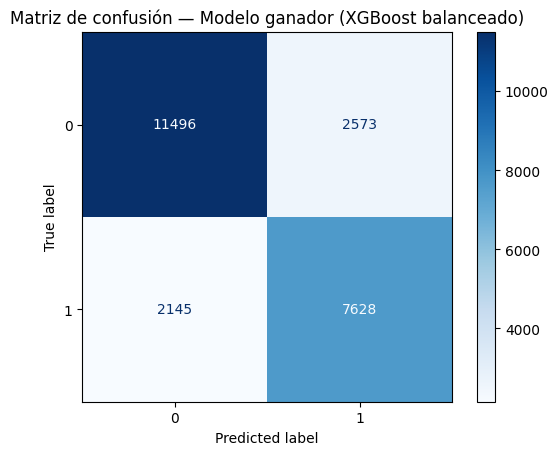

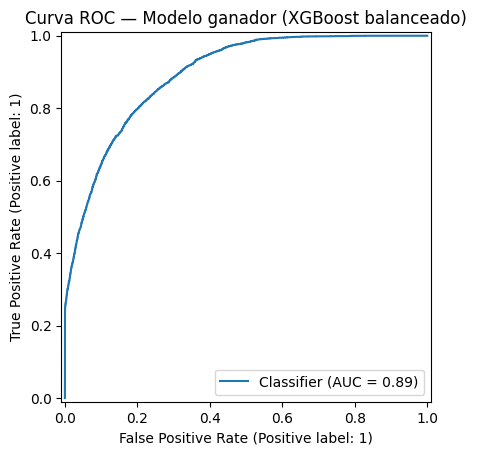

In [177]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_ganador, cmap="Blues")
plt.title("Matriz de confusión — Modelo ganador (XGBoost balanceado)")
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob_ganador)
plt.title("Curva ROC — Modelo ganador (XGBoost balanceado)")
plt.show()

La matriz de confusión muestra que, de las 23.842 reservas del conjunto de test, el modelo clasifica correctamente 11.496 reservas que no se cancelan y 7.628 que sí lo hacen. Los errores se reparten en 2.145 cancelaciones reales que el modelo no detecta y 2.573 reservas que se marcan como posible cancelación sin llegar a producirse. En términos relativos, el modelo deja escapar aproximadamente un 22 % de las cancelaciones reales, mientras que sobre el total de reservas que finalmente no se cancelan, alrededor de un 18 % recibe una alerta que no llega a materializarse. Este reparto, más equilibrado entre ambos tipos de error que el que mostraba la versión optimizada con Optuna, es coherente con el criterio fijado en el 9.2 de priorizar un buen equilibrio entre precision y recall en lugar de maximizar solo una de las dos. La curva ROC, con un área bajo la curva de 0,89, confirma que el modelo mantiene una capacidad de discriminación alta, muy próxima a la del resto de modelos comparados en el apartado 9.1.

---
## 10. Interpretabilidad


Analizo los resultados analizando como se comportan las variables.

Identifico las variables que mas importancia tienen y en que sentido influyen al la variable objetivo.

### 10.1. Importancia global de las variables

Utilizo SHAP para analizar qué variables influyen más en las predicciones del modelo ganador y en qué sentido lo hacen. Como el modelo es XGBoost, uso `TreeExplainer`, que está optimizado para modelos basados en árboles y calcula los valores SHAP de forma mucho más rápida que un explainer genérico. Dado que el conjunto de test tiene más de 23.000 reservas, calculo el resumen global sobre una muestra de 2.000 reservas en lugar de sobre el conjunto completo, ya que para ver el patrón general de importancia de las variables no hace falta usar todas las filas, y esto reduce bastante el tiempo de cálculo.

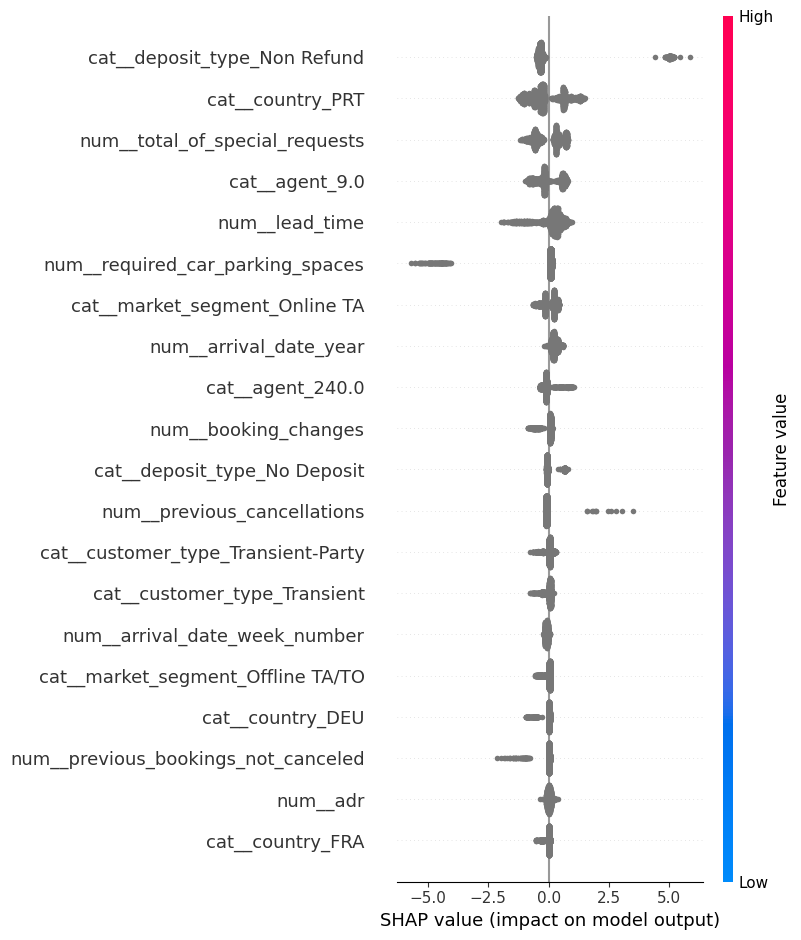

In [168]:
# Extraigo el preprocesado y el modelo entrenado dentro del pipeline ganador.
preprocesador_ganador = modelo_ganador.named_steps["preprocesado"]
modelo_shap = modelo_ganador.named_steps["modelo"]

# Transformo el conjunto de test manteniendo el mismo formato disperso que usa el propio
# pipeline al entrenar y predecir, para que XGBoost interprete los ceros exactamente igual
# que en el resto del notebook.
X_test_transformado = preprocesador_ganador.transform(X_test)

# Obtengo los nombres de las variables después del preprocesado.
nombres_variables = preprocesador_ganador.get_feature_names_out()

# Creo el explainer para modelos basados en árboles.
explainer = shap.TreeExplainer(modelo_shap)

# Tomo una muestra del conjunto de test para agilizar el cálculo del resumen global.
np.random.seed(RANDOM_STATE)
indices_muestra = np.random.choice(X_test_transformado.shape[0], size=2000, replace=False)
X_test_muestra = X_test_transformado[indices_muestra]

# Calculo los valores SHAP sobre la muestra.
shap_values_muestra = explainer(X_test_muestra)
shap_values_muestra.feature_names = list(nombres_variables)

# Represento el resumen global de importancia de las variables.
shap.summary_plot(shap_values_muestra.values, X_test_muestra, feature_names=nombres_variables)

La variable con más peso con diferencia sigue siendo el tipo de depósito no reembolsable, cuyos puntos llegan hasta valores SHAP de 5 o 6, muy por encima del resto. Le siguen el país Portugal, el número de peticiones especiales, un agente concreto identificado como 9, la antelación de la reserva y las plazas de parking solicitadas, esta última con un efecto muy fuerte en sentido contrario, empujando hacia valores de SHAP de hasta -6. Este orden de importancia coincide de forma prácticamente exacta con el que ya se había observado en el análisis anterior, lo que confirma que este patrón de riesgo no es un efecto puntual de un modelo concreto, sino una relación consistente que aparece en los datos independientemente del ajuste fino de hiperparámetros. El resto de variables, como el año de llegada, el segmento de mercado online, otro agente concreto identificado como 240, los cambios en la reserva o las cancelaciones previas, mantienen un peso claramente menor sobre la predicción del modelo.

### 10.2. Explicación individual de dos reservas concretas

Para cumplir con lo que pide el enunciado, elijo dos reservas del conjunto de test que representen los dos extremos del riesgo estimado por el modelo, la que tiene la probabilidad de cancelación más alta y la que tiene la más baja, y utilizo un gráfico de tipo waterfall para ver qué variables concretas empujan la predicción de cada una hacia arriba o hacia abajo.

Probabilidad de cancelación de la reserva de mayor riesgo: 0.9990
Probabilidad de cancelación de la reserva de menor riesgo: 0.0003


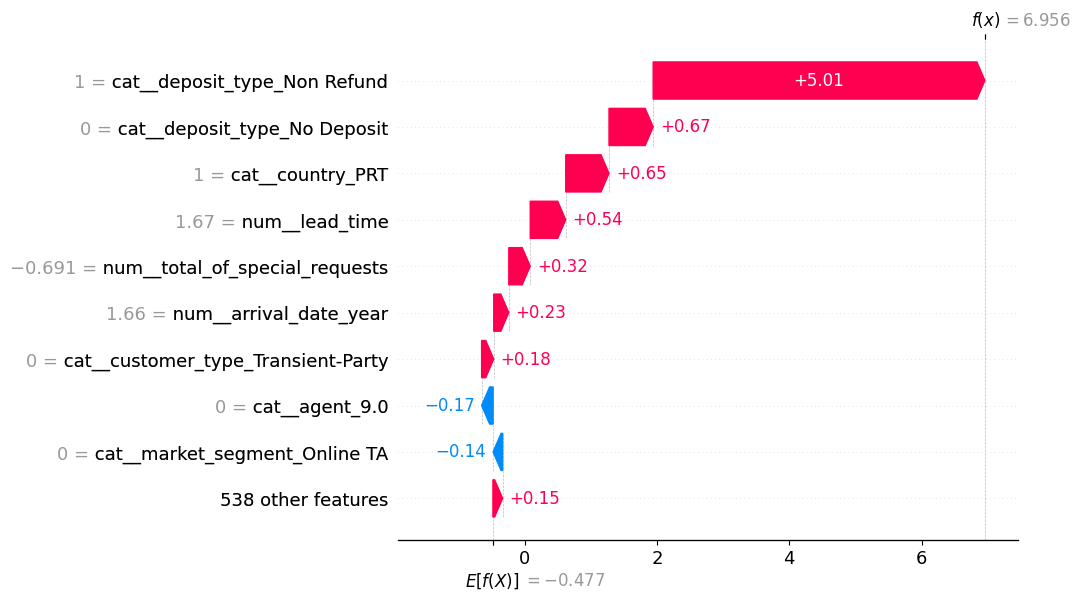

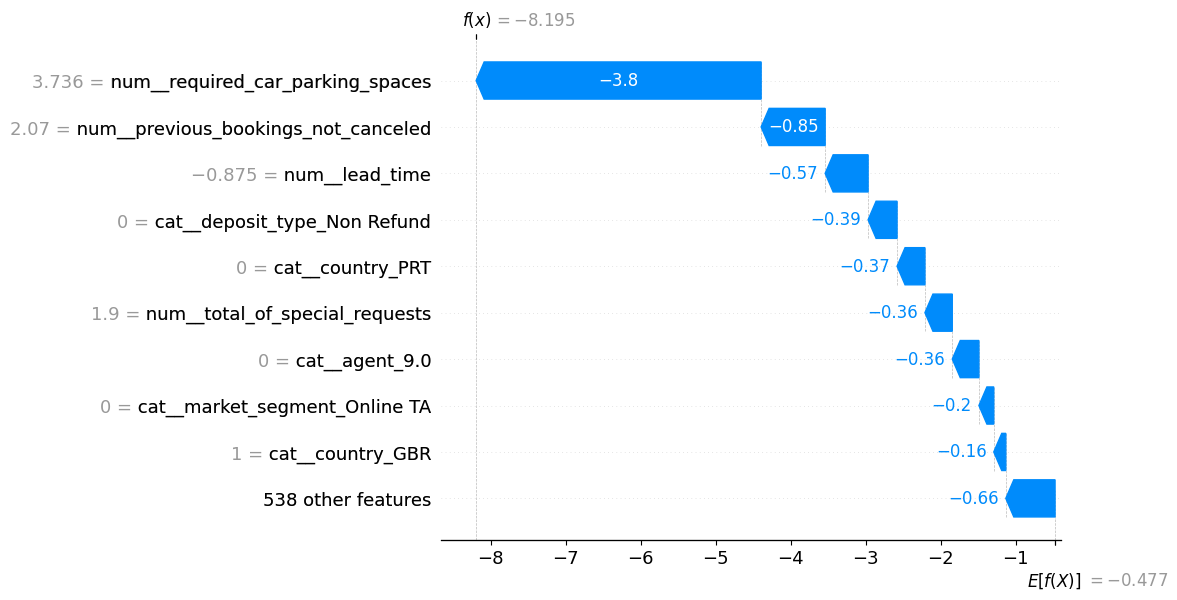

In [179]:
# Selecciono la reserva con mayor y con menor probabilidad de cancelación prevista por el modelo.
indice_riesgo_alto = np.argmax(y_prob_xgb_opt)
indice_riesgo_bajo = np.argmin(y_prob_xgb_opt)

print(f"Probabilidad de cancelación de la reserva de mayor riesgo: {y_prob_xgb_opt[indice_riesgo_alto]:.4f}")
print(f"Probabilidad de cancelación de la reserva de menor riesgo: {y_prob_xgb_opt[indice_riesgo_bajo]:.4f}")

# Calculo los valores SHAP únicamente para estas dos reservas concretas.
explicacion_dos_reservas = explainer(X_test_transformado[[indice_riesgo_alto, indice_riesgo_bajo]])
explicacion_dos_reservas.feature_names = list(nombres_variables)

# Represento la reserva de mayor riesgo.
shap.plots.waterfall(explicacion_dos_reservas[0])

# Represento la reserva de menor riesgo.
shap.plots.waterfall(explicacion_dos_reservas[1])

En la reserva de mayor riesgo, con una probabilidad de cancelación de 0,9990, el factor que domina por completo es tener un depósito no reembolsable, que por sí solo aporta +5,01 al resultado. Le siguen en importancia proceder de Portugal, con +0,65, una antelación larga, con +0,54, y tener pocas peticiones especiales, con +0,32, mientras que el resto de variables tienen una contribución mucho más pequeña.

En la reserva de menor riesgo, con una probabilidad de 0,0003, el factor que más reduce el riesgo es haber solicitado varias plazas de parking, que aporta -3,80, seguido de tener un historial de reservas previas no canceladas, con -0,85, y una antelación corta, con -0,57. Al igual que ocurría con el modelo anterior, las dos variables que más pesan en cada reserva son opuestas entre sí, el depósito no reembolsable dispara el riesgo en la reserva que finalmente se cancela, y las plazas de parking, asociadas a una necesidad concreta del viaje, lo reducen con fuerza en la reserva que se mantiene, lo que indica que este patrón no depende de un modelo en particular, sino que es una relación consistente en los propios datos.

### 10.3. Conclusión de negocio: perfil de reserva de mayor riesgo

El perfil de reserva con mayor riesgo de cancelación es el de una reserva con depósito no reembolsable, procedente de Portugal, con una antelación larga respecto a la fecha de llegada y con pocas peticiones especiales asociadas. El hallazgo del depósito no reembolsable resulta llamativo porque en principio cabría esperar que disuadiera la cancelación, pero el modelo muestra justo lo contrario, lo que sugiere que este tipo de depósito está asociado a reservas gestionadas por canales o agentes concretos que terminan sin confirmarse, más que a una decisión directa del huésped final.

En el extremo opuesto, el perfil de menor riesgo corresponde a reservas con una antelación corta, con varias peticiones especiales, y sobre todo con necesidades concretas para la estancia, como solicitar plazas de parking, así como a clientes con un historial previo de reservas completadas sin cancelar. Este mismo patrón se ha observado tanto en el modelo optimizado con Optuna como en el modelo balanceado finalmente elegido como ganador, lo que refuerza la fiabilidad del hallazgo, ya que no depende de la configuración concreta de un único modelo. Desde el punto de vista del equipo de Revenue Management, esto sugiere que las señales más útiles para anticipar una cancelación no son tanto los datos generales del cliente, sino las condiciones concretas bajo las que se ha hecho la reserva y el canal a través del cual ha llegado.

---

## 11. Sistema de aviso de riesgo de cancelación

Una vez seleccionado el modelo ganador, construyo una función que, a partir de las probabilidades de cancelación que calcula el modelo, clasifica cada reserva en un nivel de riesgo y propone la acción preventiva que correspondería según el escenario planteado en el enunciado, es decir, upgrades con descuento, depósito no reembolsable o ajuste de la política de overbooking.

### 11.1. Clasificación de reservas por nivel de riesgo

In [171]:
# Calculo la probabilidad de cancelación de cada reserva del conjunto de test con el modelo ganador.
probabilidades_riesgo = modelo_ganador.predict_proba(X_test)[:, 1]

# Defino los umbrales de riesgo y la acción preventiva asociada a cada nivel.
def clasificar_riesgo(probabilidad):
    if probabilidad >= 0.70:
        return "Alto", "Solicitar depósito no reembolsable"
    elif probabilidad >= 0.40:
        return "Medio", "Ofrecer upgrade con descuento"
    else:
        return "Bajo", "Sin acción preventiva"

# Aplico la clasificación a todas las reservas del conjunto de test.
niveles_riesgo = [clasificar_riesgo(p) for p in probabilidades_riesgo]

aviso_reservas = X_test.copy()
aviso_reservas["probabilidad_cancelacion"] = probabilidades_riesgo
aviso_reservas["nivel_riesgo"] = [nivel for nivel, accion in niveles_riesgo]
aviso_reservas["accion_recomendada"] = [accion for nivel, accion in niveles_riesgo]

# Compruebo cuántas reservas caen en cada nivel de riesgo.
print(aviso_reservas["nivel_riesgo"].value_counts())

# Muestro un ejemplo de reservas de riesgo alto.
display(aviso_reservas[aviso_reservas["nivel_riesgo"] == "Alto"].head())

nivel_riesgo
Bajo     13637
Alto      6347
Medio     3858
Name: count, dtype: int64


,hotel,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,total_guests,total_nights,is_long_stay,probabilidad_cancelacion,nivel_riesgo,accion_recomendada
95368,City Hotel,393,2017,April,16,22,2,1,2,0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,0,Non Refund,229.0,0,Transient,90.0000,0,0,2,3,0,0.9984,Alto,Solicitar depósito no reembolsable
95369,City Hotel,206,2017,April,16,22,2,1,1,0,0,BB,ROU,Online TA,TA/TO,0,0,0,A,0,No Deposit,9.0,0,Transient,109.8000,0,0,1,3,0,0.8709,Alto,Solicitar depósito no reembolsable
95370,City Hotel,393,2017,April,16,22,2,1,2,0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,0,Non Refund,229.0,0,Transient,90.0000,0,0,2,3,0,0.9984,Alto,Solicitar depósito no reembolsable
95371,City Hotel,393,2017,April,16,22,2,1,2,0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,0,Non Refund,229.0,0,Transient,90.0000,0,0,2,3,0,0.9984,Alto,Solicitar depósito no reembolsable
95372,City Hotel,393,2017,April,16,22,2,1,2,0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,0,Non Refund,229.0,0,Transient,90.0000,0,0,2,3,0,0.9984,Alto,Solicitar depósito no reembolsable


De las 23.842 reservas del conjunto de test, el modelo clasifica 6.347 como riesgo alto, un 26,62 % del total, 3.858 como riesgo medio, un 16,18 %, y 13.637 como riesgo bajo, el 57,20 % restante. Esta distribución resulta manejable desde el punto de vista operativo, porque el grupo de riesgo alto, sobre el que se aplicaría la acción más costosa, solicitar un depósito no reembolsable, representa algo más de una cuarta parte del total de reservas, y no la mayoría, lo que evita que la alerta se convierta en la norma general en lugar de una excepción sobre la que actuar. El ejemplo de reservas de riesgo alto que se muestra confirma además el patrón detectado en el apartado 10, ya que varias de ellas comparten exactamente el mismo perfil: origen en Portugal y depósito de tipo Non Refund, con probabilidades de cancelación superiores al 98 %.

### 11.2. Función de evaluación de una reserva nueva

Para que el sistema funcione no solo sobre el conjunto de test sino también sobre una reserva nueva que todavía no existe en el dataset, uso la misma lógica y lo aplico en una función que recibe una única reserva para que lo analice:

In [172]:
# Función para evaluar el riesgo de una reserva nueva a partir de sus datos.
def evaluar_nueva_reserva(datos_reserva):
    probabilidad = modelo_ganador.predict_proba(datos_reserva)[:, 1][0]
    nivel, accion = clasificar_riesgo(probabilidad)
    print(f"Probabilidad de cancelación: {probabilidad:.4f}")
    print(f"Nivel de riesgo: {nivel}")
    print(f"Acción recomendada: {accion}")

### 11.3. Representación de las reservas respecto al nivel de riesgo

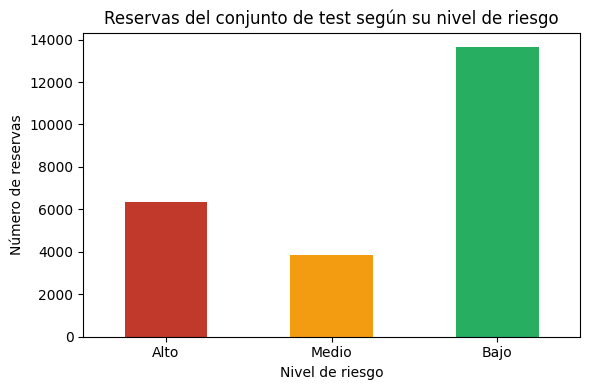

In [173]:
# Represento cuántas reservas del conjunto de test caen en cada nivel de riesgo.
plt.figure(figsize=(6, 4))
aviso_reservas["nivel_riesgo"].value_counts().reindex(["Alto", "Medio", "Bajo"]).plot(kind="bar", color=["#c0392b", "#f39c12", "#27ae60"])
plt.title("Reservas del conjunto de test según su nivel de riesgo")
plt.xlabel("Nivel de riesgo")
plt.ylabel("Número de reservas")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

El gráfico confirma de forma visual la misma distribución obtenida en el 11.1, con el grupo de riesgo bajo claramente por encima de los otros dos, seguido del grupo de riesgo alto y, por último, el de riesgo medio como el menos numeroso de los tres. Esta forma de reparto, con más de la mitad de las reservas en riesgo bajo, respalda la idea de que el sistema de aviso no generaría una alerta indiscriminada sobre la mayoría de las reservas, sino que concentraría la atención del equipo de Revenue Management en un grupo más reducido y manejable de casos.

### 11.4. Impacto económico de no detectar una cancelación

In [174]:
# Estimo el ingreso en juego en las reservas de riesgo alto que finalmente se cancelan.
reservas_riesgo_alto = aviso_reservas[aviso_reservas["nivel_riesgo"] == "Alto"].copy()
reservas_riesgo_alto["cancelada_real"] = y_test.loc[reservas_riesgo_alto.index]

ingreso_en_riesgo = (
    reservas_riesgo_alto[reservas_riesgo_alto["cancelada_real"] == 1]["adr"]
    * reservas_riesgo_alto[reservas_riesgo_alto["cancelada_real"] == 1]["total_nights"]
).sum()

print(f"Ingreso estimado en riesgo por cancelaciones no evitadas en el grupo de riesgo alto: {ingreso_en_riesgo:.2f} €")

Ingreso estimado en riesgo por cancelaciones no evitadas en el grupo de riesgo alto: 2840390.44 €


El importe estimado en riesgo por cancelaciones no evitadas dentro del grupo de riesgo alto asciende a 2.840.390,44 €. Esta cifra corresponde únicamente a las reservas de riesgo alto que finalmente sí se cancelan, y representa el ingreso que se perdería si el hotel no tomara ninguna medida preventiva sobre estas reservas. Es precisamente esta cantidad la que justifica, desde una perspectiva de negocio, invertir en acciones como solicitar un depósito no reembolsable o contactar de forma proactiva con estos clientes, ya que el coste de dichas acciones preventivas es previsiblemente muy inferior al ingreso que está en juego.

### 11.5. Creación de un archivo para exportar la tabla de avisos

In [175]:
# Exporto la tabla de avisos para que pueda entregarse al equipo de Revenue Management.
aviso_reservas[["nivel_riesgo", "probabilidad_cancelacion", "accion_recomendada"]].to_excel("avisos_riesgo_cancelacion.xlsx", index=True)
print("Archivo avisos_riesgo_cancelacion.xlsx generado correctamente.")

Archivo avisos_riesgo_cancelacion.xlsx generado correctamente.


---
## 12. Conclusiones y próximos pasos



### 12.1. Resumen del problema y del proceso seguido

Este trabajo parte de la necesidad del equipo de Revenue Management de una cadena hotelera con dos propiedades en Portugal de anticipar, en el momento de la reserva, qué clientes tienen una probabilidad alta de cancelar, con el objetivo de activar acciones preventivas como upgrades con descuento, depósitos no reembolsables o ajustes en la política de overbooking. Para ello se ha utilizado el dataset Hotel Booking Demand, con cerca de 119.000 reservas entre julio de 2015 y agosto de 2017, sobre el que se ha realizado un análisis exploratorio, una limpieza de valores nulos y anomalías justificada caso por caso, la eliminación de variables con fuga de información como el estado de la reserva o el tipo de habitación finalmente asignada, y la creación de nuevas variables como el número total de huéspedes o de noches. A partir de ahí se han entrenado y comparado cuatro modelos de clasificación, evaluando también el efecto de corregir el desbalanceo de clases, y se ha optimizado el modelo más prometedor mediante una búsqueda de hiperparámetros con Optuna, respetando en todo momento el orden cronológico de las reservas.

### 12.2. Principales hallazgos del análisis exploratorio

El análisis exploratorio muestra que el riesgo de cancelación no se reparte de forma homogénea entre reservas. El City Hotel presenta una tasa de cancelación del 41,8 %, muy superior al 27,8 % del Resort Hotel, lo que sugiere un perfil de cliente distinto entre ambos establecimientos. La antelación de la reserva también es un factor determinante, con una tasa de cancelación que crece de forma prácticamente escalonada, desde un 9,6 % en reservas hechas con menos de una semana de antelación hasta un 67,65 % en las que se hacen con más de un año de antelación. El canal de distribución muestra igualmente diferencias notables, con una tasa de cancelación del 41,1 % en el canal de agencias y touroperadores frente a un 17,5 % en el canal directo, lo que indica que las reservas gestionadas por intermediarios son sistemáticamente más inestables que las realizadas directamente por el cliente. Por último, el precio medio por noche resulta ligeramente superior en las reservas que acaban cancelándose, 105,02 € frente a 100,17 €, aunque esta diferencia es mucho menos determinante que la antelación o el canal de distribución.

### 12.3. Modelo ganador y variables más determinantes

De los cuatro algoritmos evaluados, XGBoost ha obtenido de forma consistente el mejor equilibrio entre precision y recall, tanto en su versión inicial como en la balanceada, por lo que ha sido el modelo elegido para la optimización de hiperparámetros con Optuna. Sin embargo, tras comparar todas las versiones en el apartado 9, el modelo que mejor cumple el criterio de equilibrio entre precision y recall fijado para este problema de negocio resulta ser XGBoost balanceado, y no la versión optimizada, ya que esta última mejora la capacidad general de discriminación del modelo pero a costa de un recall notablemente más bajo. El modelo final, entrenado ajustando el peso de la clase minoritaria mediante `scale_pos_weight`, obtiene sobre el conjunto de test una accuracy de 0,8021, una precision de 0,7478, un recall de 0,7805, un F1-score de 0,7638 y un ROC-AUC de 0,8931, lo que significa que detecta correctamente algo más de siete de cada diez reservas que finalmente se cancelan. El análisis de interpretabilidad con SHAP muestra que la variable más determinante con diferencia es el tipo de depósito no reembolsable, que empuja con mucha fuerza la predicción hacia la cancelación, un resultado que en principio resulta contraintuitivo pero que probablemente está asociado a reservas gestionadas por ciertos canales o agencias que terminan sin confirmarse. Le siguen en importancia el país de origen de la reserva, la antelación con la que se realiza y el número de plazas de parking solicitadas, esta última asociada a un menor riesgo, ya que refleja una necesidad concreta y personal del viaje que suele acompañar a estancias que sí se llegan a completar.

### 12.4. Propuesta de negocio

A partir del modelo ganador se ha construido un sistema de aviso que clasifica cada reserva en un nivel de riesgo alto, medio o bajo, y le asigna una acción preventiva concreta, coherente con el planteamiento inicial del caso: solicitar un depósito no reembolsable en las reservas de mayor riesgo y ofrecer un upgrade con descuento en las de riesgo intermedio. Sobre el conjunto de test, este sistema clasifica un 26,62 % de las reservas como riesgo alto, un 16,18 % como riesgo medio y el 57,20 % restante como riesgo bajo, un reparto que permite concentrar el esfuerzo del equipo de Revenue Management en poco más de una cuarta parte de las reservas en lugar de generar una alerta generalizada. El impacto económico de no actuar sobre las reservas de riesgo alto que finalmente se cancelan se ha estimado en 2.840.390,44 €, una cifra que respalda por sí sola la inversión en las acciones preventivas propuestas, ya que su coste es previsiblemente muy inferior al ingreso que está en juego. Además, se ha preparado una función que permite aplicar esta misma clasificación a una reserva nueva en el momento en que se realiza, y se ha dejado lista una exportación de la tabla de avisos en formato Excel para que pueda entregarse directamente al equipo de negocio.